In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
import matplotlib.gridspec as gridspec
import matplotlib.colors as mcolors
from matplotlib.colorbar import Colorbar
from matplotlib.legend_handler import HandlerTuple
from matplotlib import colors
from scipy import special
from scipy.stats import linregress
from scipy.optimize import curve_fit
from mycolorpy import colorlist as mcp
from pathlib import Path
import pandas as pd
import matplotlib as mpl
import glob 
import os
import h5py


plt.rcParams["text.usetex"] = True
plt.rcParams["text.latex.preamble"] = r"\usepackage{amsmath}\usepackage{xcolor}"
plt.rcParams["font.family"] = "lmodern"

In [4]:
cwd = Path().resolve()
project_root = cwd.parent

data_equilibrium_dir = project_root / "data" / "equilibrium"
data_quench_dir = project_root / "data" / "quench" / "quench_paper"
data_quench_NNN_dir = project_root / "data" / "quench" / "quench_paper" / "NNN"
plot_dir = project_root / "plot"/"figures"/"figures_paper"
checkpoint_dir = project_root / "checkpoints" / "quench" / "quench_paper"

In [7]:
def set_zero_at(ax, dmin, dmax, frac, pad=1.08):
    """Set y-limits so that y = 0 sits at fraction `frac` of the axis height
    (0 = bottom, 0.5 = middle) and all the data fit."""
    L = 0.0
    if dmax > 0:
        L = max(L, dmax / (1 - frac))
    if dmin < 0 and frac > 0:
        L = max(L, -dmin / frac)
    L *= pad
    ax.set_ylim(-frac * L, (1 - frac) * L)


def figure_1_paper():

    with plt.rc_context(APS_RC):

        # ------------------------------------------------------------ data
        df1 = pd.read_csv(data_quench_dir / "NNN/quench_NN_ctr-N300_FillingFraction0.16666666666666666_t20.0_V1.0_entr_evrey_1_entanglement.csv")
        df2 = pd.read_csv(data_quench_dir / "NNN/quench_NN_ctr-N300_FillingFraction0.16666666666666666_t20.0_V0.5_entr_evrey_1_entanglement.csv")
        df3 = pd.read_csv(data_quench_dir / "NNN/quench_NN_ctr-N300_FillingFraction0.16666666666666666_t20.0_V1.0_fluctuations.csv")
        df4 = pd.read_csv(data_quench_dir / "NNN/quench_NN_ctr-N300_FillingFraction0.16666666666666666_t20.0_V0.5_fluctuations.csv")

        times1, Entropy1 = df1["Time"].values, df1["Entropy"].values
        times2, Entropy2 = df2["Time"].values, df2["Entropy"].values
        times3, Fluctuations3 = df3["Time"].values, df3["Variance"].values
        times4, Fluctuations4 = df4["Time"].values, df4["Variance"].values

        # Delta X(t) = X(t) - X(0), in units of 10^-3 (the factor is written at the top of the axes)
        scale = 1e3
        dS1 = (Entropy1 - Entropy1[0]) * scale
        dS2 = (Entropy2 - Entropy2[0]) * scale
        dF3 = (Fluctuations3 - Fluctuations3[0]) * scale
        dF4 = (Fluctuations4 - Fluctuations4[0]) * scale

        # ------------------------------------------------------------ figure
        fig, ax1 = plt.subplots(figsize=(3.4, 2.7))
        ax2 = ax1.twinx()

        lw = 1.2
        color_S = 'tab:blue'
        color_F = 'dimgray'

        # solid = first quench, dashed = second quench
        l1, = ax1.plot(times1, dS1, color=color_S, linestyle='-', linewidth=lw)
        l2, = ax1.plot(times2, dS2, color=color_S, linestyle='--', linewidth=lw)
        l3, = ax2.plot(times3, dF3, color=color_F, linestyle='-', linewidth=lw)
        l4, = ax2.plot(times4, dF4, color=color_F, linestyle='--', linewidth=lw)

        # thin line marking Delta F = 0 on the right axis
        ax2.axhline(0, color=color_F, linewidth=0.6, alpha=0.6)

        # ------------------------------------------------------------ y-limits
        # fraction of the axis height at which y = 0 sits:
        #   zero_frac_S = 0.0 -> entropy starts from the bottom, fluctuations from the middle
        #                        (offset layout: the four curves do not start on top of each other)
        #   zero_frac_S = zero_frac_F -> the two zeros coincide
        zero_frac_S = 0.0
        zero_frac_F = 0.5
        set_zero_at(ax1, min(dS1.min(), dS2.min()), max(dS1.max(), dS2.max()), zero_frac_S)
        set_zero_at(ax2, min(dF3.min(), dF4.min()), max(dF3.max(), dF4.max()), zero_frac_F)
        ax1.set_xlim(0, times1.max())

        # ------------------------------------------------------------ axes styling
        ax1.set_xlabel(r"Time $t$")
        ax1.set_ylabel(r"$\Delta S_A(t)$", color=color_S, fontsize=12)
        ax2.set_ylabel(r"$\Delta\mathcal{F}_A(t)$", color=color_F, labelpad = 0, fontsize=12)

        # only the numbers are colored; ticks and spines stay black
        ax1.tick_params(axis='y', which='both', labelcolor=color_S,
                        direction='in', left=True, right=False)
        ax2.tick_params(axis='y', which='both', labelcolor=color_F,
                        direction='in', left=False, right=True)
        ax1.tick_params(axis='x', which='both', direction='in', top=True)

        ax1.yaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))
        ax2.yaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))

        # scale factors at the top of each axis, not in the labels
        ax1.text(0.0, 1.01, r"$\times 10^{-3}$", transform=ax1.transAxes,
                 ha='left', va='bottom', fontsize=8, color=color_S)
        ax2.text(1.0, 1.01, r"$\times 10^{-3}$", transform=ax2.transAxes,
                 ha='right', va='bottom', fontsize=8, color=color_F)

        # ------------------------------------------------------------ legend
        # attached to ax2 (top-most axes) so that no curve is drawn over it
        ax2.legend(
            [(l1, l3), (l2, l4)],
            [r"$V/t_0:\ 0.5 \to 0.25$",
             r"$V/t_0:\ 0.25 \to 0.5$"],
            loc='upper left', frameon=True, edgecolor='lightgray',
            handler_map={tuple: HandlerTuple(ndivide=None)},
            handlelength=2.4, borderpad=0.4, labelspacing=0.3, fontsize=6.2
        )

        fig.tight_layout(pad=0.3)
        fig.savefig(plot_dir / "figure_1_poster.pdf")
        fig.savefig(plot_dir / "figure_1_posterpng", dpi=300)
        plt.show()

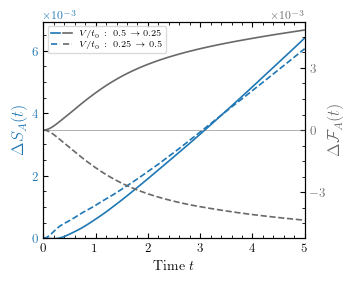

In [8]:
figure_1_paper()

In [25]:

def figure_2_paper(): 
    
    df = pd.read_csv(data_quench_dir / "NNN/quench_NN_ctr-N400_t20.0_V0.7.csv" )
    df1 = pd.read_csv(data_quench_dir / "NNN/quench_NN_ctr-N800_t20.0_V0.7.csv")
    df2 = pd.read_csv(data_quench_dir / "NNN/quench_NN_ctr-N1600_t20.0_V0.7.csv")

    times = df["Time"].values
    Fluctuations = df["Variance"].values

    times1 = df1["Time"].values
    Fluctuations1 = df1["Variance"].values

    times2 = df2["Time"].values
    Fluctuations2 = df2["Variance"].values
    

    # --- Param Bethe Ansatz---
    # mu_i = np.arccos(V_i / 2)
    # mu_f = np.arccos(V_f / 2)

    # K_i_BA = np.pi / (2 * (np.pi - mu_i))
    # K_f_BA = np.pi / (2 * (np.pi - mu_f))

    def compute_LL_parameter(filling, V, t_0, t_2):
        fermi_velocity = 2 * t_0 * np.sin(np.pi * filling) + 4 * t_2 * np.sin(2 * np.pi * filling)
        numerator = fermi_velocity 
        denominator = fermi_velocity + (2* V / np.pi) * (1 - np.cos(2 * np.pi * filling))
        return np.sqrt(numerator / denominator)

    V_i = 0.7
    V_f = 0.5
    filling = 0.5
    t_0 = 1.0 
    t_2 = 0.0

    # --- Param Bethe Ansatz---
    mu_i = np.arccos(V_i / 2)
    mu_f = np.arccos(V_f / 2)

    K_i_BA = np.pi / (2 * (np.pi - mu_i))
    K_f_BA = np.pi / (2 * (np.pi - mu_f))

    K_i = compute_LL_parameter(filling, V_i, t_0, t_2)
    K_f = compute_LL_parameter(filling, V_f, t_0, t_2)
    
    print(f"k_05 = {K_f:.6f}")
    print(K_f)

    B_param = 0.5 * (K_i**2 - K_f**2) / (K_i * K_f)
    m_theory = - B_param * K_f / ( np.pi**2)

    B_param_BA = 0.5 * (K_i_BA**2 - K_f_BA**2) / (K_i_BA * K_f_BA)
    m_theory_BA = - B_param_BA * K_f_BA / ( np.pi**2)  

    Fluctuations = Fluctuations - Fluctuations[0]  
    Fluctuations = Fluctuations[1:]
    times = times[1:]

    Fluctuations1 = Fluctuations1 - Fluctuations1[0]  
    Fluctuations1 = Fluctuations1[1:]
    times1 = times1[1:]

    Fluctuations2 = Fluctuations2 - Fluctuations2[0]  
    Fluctuations2 = Fluctuations2[1:]
    times2 = times2[1:]

    # --- perform fit ---
    mask = (times2 >= 2.0) & (times2 <= 3.0)
    times_fit = times2[mask]
    Fluctuations_fit = Fluctuations2[mask]
    x_data = np.log(times_fit)
    y_data = Fluctuations_fit
    slope, intercept, r_value, p_value, std_err = linregress(x_data, y_data)
    
    print(f"Fit Results: slope = {slope:.6f}, intercept = {intercept:.6f}, R-squared = {r_value**2:.6f}")
    print(f"m_theory:  {m_theory:.6f}, m_fit: {slope:.6f}, error_percentage: {abs((slope - m_theory)/m_theory)*100:.2f}%")
    
    t_line = np.linspace(0.5, 7, 200)
    # fit_curve = slope * np.log(t_line) + intercept
    theory_curve = m_theory * np.log(t_line) + intercept
    theory_curve_BA = m_theory_BA * np.log(t_line) + intercept

    # --- Plotting ---
    fig = plt.figure(figsize=(8, 5))
    spec = gridspec.GridSpec(nrows=1, ncols=1)
    ax = fig.add_subplot(spec[0, 0])

    # Plot data using open markers and no connecting lines to mimic Fig 4
    # The 'markevery' parameter prevents the markers from clustering too heavily if you have many data points
    m_spacing = 5
    
    l2, = ax.semilogx(times, Fluctuations, color='dodgerblue', marker='o', markerfacecolor='none', 
                      linestyle='None', markevery=m_spacing, label=r"$N=400$")
    l3, = ax.semilogx(times1, Fluctuations1, color='mediumorchid', marker='s', markerfacecolor= 'none',
                      linestyle='None', markevery=m_spacing, label=r"$N=800$")
    l4, = ax.semilogx(times2, Fluctuations2, color='royalblue', marker='p', markerfacecolor= 'none',
                          linestyle='None', markevery=m_spacing, label=r"$N=1600$")
    
    # Plot theory as a dashed black line, similar to the reference lines in the paper
    l5, = ax.semilogx(t_line, theory_curve, color='black', linestyle='--', linewidth=1.0, label=r'PT and $n= 0.5$')
    l5, = ax.semilogx(t_line, theory_curve_BA, color='red', linestyle='--', linewidth=1.0, label=r'Bethe Ansatz')

    # Axes and grid styling
    ax.set_xlabel(r"time $t$", fontsize=16)
    ax.set_ylabel(r"$\Delta \mathcal{F}(t)$", fontsize=16)
    ax.tick_params(axis='both', which='major', direction='in', labelsize=14)
    ax.tick_params(axis='both', which='minor', direction='in')
    ax.set_xlim(0.4, 5.5)
    ax.set_ylim(0.005, 0.025)
    
    # Keeping grid subtle
    ax.grid(True, which="major", linestyle='--', alpha=0.4)
    ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0), useMathText=True)
    ax.yaxis.get_offset_text().set_fontsize(14)
    
    # Legend
    leg = ax.legend(handles=[l2, l3, l4], fontsize=20, loc='best', frameon=True, edgecolor= 'lightgray')

    # --- Adding the Annotation Arrow ---
    target_x = 0.7
    target_y = intercept - 0.0018
    
    # Adjust xytext to move the starting point of the text/arrow. 
    # Here it places the text slightly to the left (0.6) and up (+0.003) from the line.
    text_x = 0.6
    text_y = intercept + 0.001 

    ax.annotate(r"$-\frac{B_2 K_f}{\pi^2} \ln(t)$", 
                xy=(target_x, target_y), 
                xytext=(text_x, text_y), 
                arrowprops=dict(arrowstyle="->", color="black", lw=1.2),
                fontsize=14,
                ha='center', 
                va='center')


    plt.tight_layout()
    plt.savefig(plot_dir / "figure_2.pdf", dpi=300)

    plt.show()

k_05 = 0.870946
0.8709460333423513
Fit Results: slope = 0.004869, intercept = 0.012252, R-squared = 0.996965
m_theory:  0.004069, m_fit: 0.004869, error_percentage: 19.64%


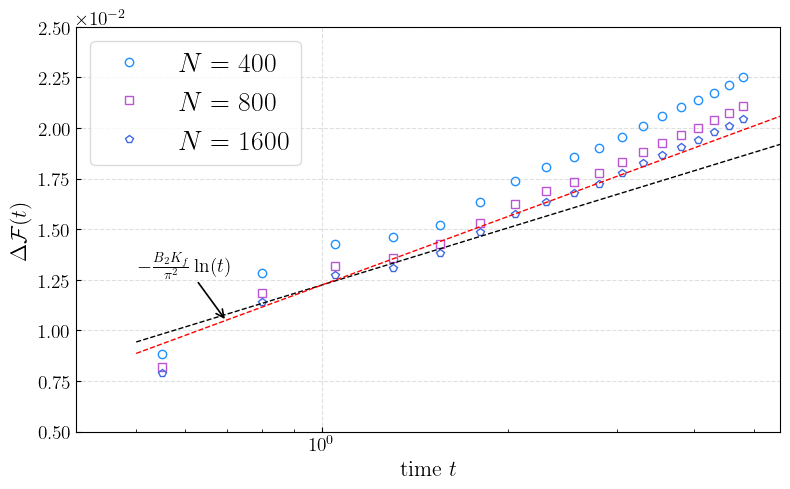

In [26]:
figure_2_paper()

In [36]:

def figure_3_paper(): 
    
    df = pd.read_csv(data_quench_dir / "NNN/quench_NNN_ctr-N400_t20.3_V0.7.csv" )
    df1 = pd.read_csv(data_quench_dir / "NNN/quench_NNN_ctr-N800_t20.3_V0.7.csv")
    df2 = pd.read_csv(data_quench_dir / "NNN/quench_NNN_ctr-N1600_t20.3_V0.7.csv")

    times = df["Time"].values
    Fluctuations = df["Variance"].values

    times1 = df1["Time"].values
    Fluctuations1 = df1["Variance"].values

    times2 = df2["Time"].values
    Fluctuations2 = df2["Variance"].values
    

    K_05 = 0.8636
    K_07 = 0.80

    print(K_05)

    K_i = K_07
    K_f = K_05

    B_param = 0.5 * (K_i**2 - K_f**2) / (K_i * K_f)
    m_theory = - B_param * K_f / ( np.pi**2) 

    Fluctuations = Fluctuations - Fluctuations[0]  
    Fluctuations = Fluctuations[1:]
    times = times[1:]

    Fluctuations1 = Fluctuations1 - Fluctuations1[0]  
    Fluctuations1 = Fluctuations1[1:]
    times1 = times1[1:]

    Fluctuations2 = Fluctuations2 - Fluctuations2[0]  
    Fluctuations2 = Fluctuations2[1:]
    times2 = times2[1:]

    # --- perform fit ---
    mask = (times2 >= 2.0) & (times2 <= 3.0)
    times_fit = times2[mask]
    Fluctuations_fit = Fluctuations2[mask]
    x_data = np.log(times_fit)
    y_data = Fluctuations_fit
    slope, intercept, r_value, p_value, std_err = linregress(x_data, y_data)
    
    #print(f"Fit Results: slope = {slope:.6f}, intercept = {intercept:.6f}, R-squared = {r_value**2:.6f}")
    #print(f"m_theory:  {m_theory:.6f}, m_fit: {slope:.6f}, error_percentage: {abs((slope - m_theory)/m_theory)*100:.2f}%")
    
    t_line = np.linspace(0.5, 7, 200)
    # fit_curve = slope * np.log(t_line) + intercept
    theory_curve = m_theory * np.log(t_line) + intercept

    # --- Plotting ---
    fig = plt.figure(figsize=(8, 5))
    spec = gridspec.GridSpec(nrows=1, ncols=1)
    ax = fig.add_subplot(spec[0, 0])

    # Plot data using open markers and no connecting lines to mimic Fig 4
    # The 'markevery' parameter prevents the markers from clustering too heavily if you have many data points
    m_spacing = 5
    
    l2, = ax.semilogx(times, Fluctuations, color='dodgerblue', marker='o', markerfacecolor='none', 
                      linestyle='None', markevery=m_spacing, label=r"$N=400$")
    l3, = ax.semilogx(times1, Fluctuations1, color='mediumorchid', marker='s', markerfacecolor= 'none',
                      linestyle='None', markevery=m_spacing, label=r"$N=800$")
    l4, = ax.semilogx(times2, Fluctuations2, color='royalblue', marker='p', markerfacecolor= 'none',
                          linestyle='None', markevery=m_spacing, label=r"$N=1600$")
    
    # Plot theory as a dashed black line, similar to the reference lines in the paper
    #l5, = ax.semilogx(t_line, theory_curve, color='black', linestyle='--', linewidth=1.0)

    # Axes and grid styling
    ax.set_xlabel(r"time $t$", fontsize=16)
    ax.set_ylabel(r"$\Delta \mathcal{F}(t)$", fontsize=16)
    ax.tick_params(axis='both', which='major', direction='in', labelsize=14)
    ax.tick_params(axis='both', which='minor', direction='in')
    ax.set_xlim(0.4, 5.5)
    ax.set_ylim(0.005, 0.025)
    
    # Keeping grid subtle
    ax.grid(True, which="major", linestyle='--', alpha=0.4)
    ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0), useMathText=True)
    ax.yaxis.get_offset_text().set_fontsize(14)
    
    # Legend
    leg = ax.legend(handles=[l2, l3, l4], fontsize=20, loc='best', frameon=True, edgecolor= 'lightgray')

    # --- Adding the Annotation Arrow ---
    target_x = 0.7
    target_y = intercept - 0.0015
    
    # Adjust xytext to move the starting point of the text/arrow. 
    # Here it places the text slightly to the left (0.6) and up (+0.003) from the line.
    


    plt.tight_layout()
    plt.savefig(plot_dir / "figure_2.pdf", dpi=300)

    plt.show()

0.8636


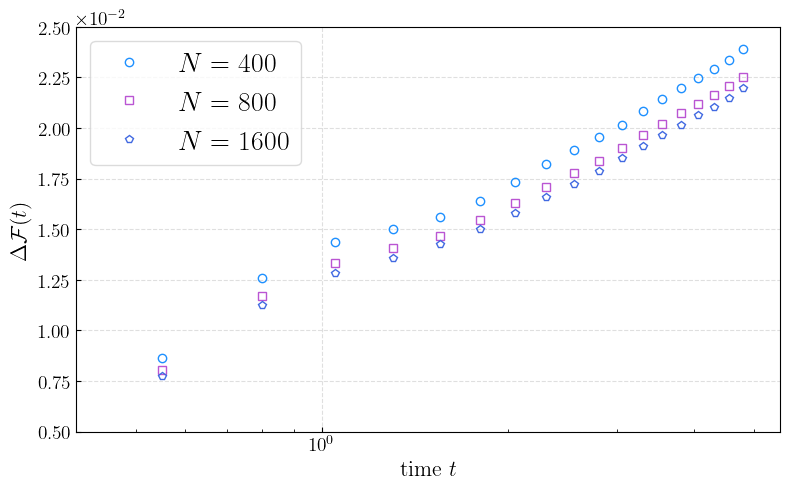

In [37]:
figure_3_paper()

In [ ]:

def figure_5_paper(): 
    
    
    df2 = pd.read_csv(data_quench_dir / "NNN/quench_NNN_ctr-N1600_FillingFraction0.25_t20.1_V0.7.csv")
    df3 = pd.read_csv(data_quench_dir / "NNN/quench_NNN_ctr-N1200_FillingFraction0.25_t20.1_V0.7.csv")

    times2 = df2["Time"].values
    Fluctuations2 = df2["Variance"].values

    times3 = df3["Time"].values
    Fluctuations3 = df3["Variance"].values

    filling = 400 / 1600
    t_0 = 1.0 
    t_2 = 0.1
    V_i = 0.7
    V_f = 0.5
    
    def compute_LL_parameter(filling, V, t_0, t_2):
        fermi_velocity = 2 * t_0 * np.sin(np.pi * filling) + 4 * t_2 * np.sin(2 * np.pi * filling)
        numerator = fermi_velocity 
        denominator = fermi_velocity + (2* V / np.pi) * (1 - np.cos(2 * np.pi * filling))
        return np.sqrt(numerator / denominator)

    def compute_LL_sound_velocity(filling, V, t_0, t_2):
        fermi_velocity = 2 * t_0 * np.sin(np.pi * filling) + 4 * t_2 * np.sin(2 * np.pi * filling)
        first_term = fermi_velocity + (V / np.pi) * np.cos(2 * np.pi * filling)
        second_term = fermi_velocity + (V / np.pi) * (2 - np.cos(2 * np.pi * filling))
        return np.sqrt(first_term * second_term)
    


    K_i = compute_LL_parameter(filling, V_i, t_0, t_2)
    K_f = compute_LL_parameter(filling, V_f, t_0, t_2)
    u_f = compute_LL_sound_velocity(filling, 0, t_0, t_2)

    print(f"Initial LL parameter: {K_i:.5f}")
    print(f"Final LL paramter: {K_f:.5f}")
    print(f"Final sound velocity: {u_f:.5f}")

    B_param = 0.5 * (K_i**2 - K_f**2) / (K_i * K_f)
    m_theory = - B_param * K_f / ( np.pi**2) 


    Fluctuations2 = Fluctuations2 - Fluctuations2[0]  
    Fluctuations2 = Fluctuations2[1:]
    times2 = times2[1:]

    Fluctuations3 = Fluctuations3 - Fluctuations3[0]
    Fluctuations3 = Fluctuations3[1:]
    times3 = times3[1:]

    # --- perform fit ---
    mask = (times2 >= 2.0) & (times2 <= 3.0)
    times_fit = times2[mask]
    Fluctuations_fit = Fluctuations2[mask]
    x_data = np.log(times_fit)
    y_data = Fluctuations_fit
    slope, intercept, r_value, p_value, std_err = linregress(x_data, y_data)
    
    #print(f"Fit Results: slope = {slope:.6f}, intercept = {intercept:.6f}, R-squared = {r_value**2:.6f}")
    #print(f"m_theory:  {m_theory:.6f}, m_fit: {slope:.6f}, error_percentage: {abs((slope - m_theory)/m_theory)*100:.2f}%")
    
    t_line = np.linspace(0.5, 7, 200)
    # fit_curve = slope * np.log(t_line) + intercept
    theory_curve = m_theory * np.log(t_line) + intercept

    # --- Plotting ---
    fig = plt.figure(figsize=(8, 5))
    spec = gridspec.GridSpec(nrows=1, ncols=1)
    ax = fig.add_subplot(spec[0, 0])

    # Plot data using open markers and no connecting lines to mimic Fig 4
    # The 'markevery' parameter prevents the markers from clustering too heavily if you have many data points
    m_spacing = 5
    
    l4, = ax.semilogx(times2, Fluctuations2, color='royalblue', marker='p', markerfacecolor= 'none',
                          linestyle='None', markevery=m_spacing, label=r"$N=1600$")
    l5, = ax.semilogx(times3, Fluctuations3, color='orchid', marker='s', markerfacecolor= 'none',
                              linestyle='None', markevery=m_spacing, label=r"$N=1200$")
    
    # Plot theory as a dashed black line, similar to the reference lines in the paper
    l6, = ax.semilogx(t_line, theory_curve, color='black', linestyle='--', linewidth=1.0, label = r" - B  ")

    # Axes and grid styling
    ax.set_xlabel(r"Time $t$", fontsize=16)
    ax.set_ylabel(r"Fluctuations $\Delta \mathcal{F}(t)$", fontsize=16)
    ax.tick_params(axis='both', which='major', direction='in', labelsize=14)
    ax.tick_params(axis='both', which='minor', direction='in')
    #ax.set_xlim(0.4, 5.5)
    #ax.set_ylim(0.005, 0.025)
    
    # Keeping grid subtle
    ax.grid(True, which="major", linestyle='--', alpha=0.4)
    ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0), useMathText=True)
    ax.yaxis.get_offset_text().set_fontsize(14)
    
    # Legend
    leg = ax.legend(handles=[l4, l5], fontsize=20, loc='best', frameon=True, edgecolor= 'lightgray')

    # --- Adding the Annotation Arrow ---
    target_x = 0.7
    target_y = intercept - 0.0015
    
    # Adjust xytext to move the starting point of the text/arrow. 
    # Here it places the text slightly to the left (0.6) and up (+0.003) from the line.
    


    plt.tight_layout()
    plt.savefig(plot_dir / "figure_5.pdf", dpi=300)

    plt.show()

Initial LL parameter: 0.89599
Final LL paramter: 0.92235
Final sound velocity: 1.81421


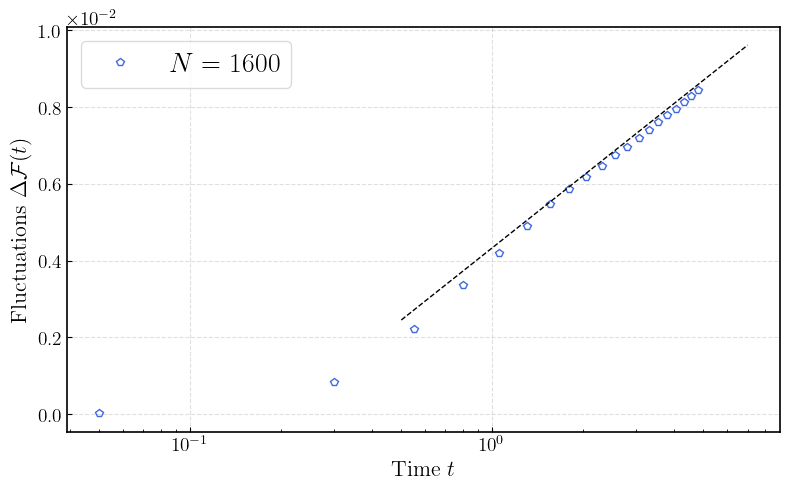

In [69]:
figure_5_paper()

In [108]:

def figure_6_paper(): 

    # APS style rcParams
    plt.rcParams.update({
        "text.usetex": True,
        "font.family": "serif",
        "font.serif": ["Computer Modern Roman"],
        "axes.linewidth": 1.1,
        "axes.labelsize": 13,
        "xtick.labelsize": 11,
        "ytick.labelsize": 11,
        "legend.fontsize": 11,
    })
    
    df2 = pd.read_csv(data_quench_dir / "NNN/quench_NN_ctr-N1600_FillingFraction0.25_t20.0_V0.7.csv")
    df3 = pd.read_csv(data_quench_dir / "NNN/quench_NN_ctr-N1200_FillingFraction0.25_t20.0_V0.7.csv")

    times2 = df2["Time"].values
    Fluctuations2 = df2["Variance"].values

    times3 = df3["Time"].values
    Fluctuations3 = df3["Variance"].values

    filling = 400 / 1600
    t_0 = 1.0 
    t_2 = 0.0
    V_i = 0.7
    V_f = 0.5
    
    def compute_LL_parameter(filling, V, t_0, t_2):
        fermi_velocity = 2 * t_0 * np.sin(np.pi * filling) + 4 * t_2 * np.sin(2 * np.pi * filling)
        numerator = fermi_velocity 
        denominator = fermi_velocity + (2* V / np.pi) * (1 - np.cos(2 * np.pi * filling))
        return np.sqrt(numerator / denominator)

    def compute_LL_sound_velocity(filling, V, t_0, t_2):
        fermi_velocity = 2 * t_0 * np.sin(np.pi * filling) + 4 * t_2 * np.sin(2 * np.pi * filling)
        first_term = fermi_velocity + (V / np.pi) * np.cos(2 * np.pi * filling)
        second_term = fermi_velocity + (V / np.pi) * (2 - np.cos(2 * np.pi * filling))
        return np.sqrt(first_term * second_term)
    


    K_i = compute_LL_parameter(filling, V_i, t_0, t_2)
    K_f = compute_LL_parameter(filling, V_f, t_0, t_2)
    u_f = compute_LL_sound_velocity(filling, V_f, t_0, t_2)

    print(f"Initial LL parameter: {K_i:.5f}")
    print(f"Final LL paramter: {K_f:.5f}")
    print(f"Final sound velocity: {u_f:.5f}")

    B_param = 0.5 * (K_i**2 - K_f**2) / (K_i * K_f)
    m_theory = - B_param * K_f / ( np.pi**2) 


    Fluctuations2 = Fluctuations2 - Fluctuations2[0]  
    Fluctuations2 = Fluctuations2[1:]
    times2 = times2[1:]

    Fluctuations3 = Fluctuations3 - Fluctuations3[0]
    Fluctuations3 = Fluctuations3[1:]
    times3 = times3[1:]

    # --- perform fit ---
    mask = (times2 >= 2.0) & (times2 <= 3.0)
    times_fit = times2[mask]
    Fluctuations_fit = Fluctuations2[mask]
    x_data = np.log(times_fit)
    y_data = Fluctuations_fit
    slope, intercept, r_value, p_value, std_err = linregress(x_data, y_data)
    
    #print(f"Fit Results: slope = {slope:.6f}, intercept = {intercept:.6f}, R-squared = {r_value**2:.6f}")
    #print(f"m_theory:  {m_theory:.6f}, m_fit: {slope:.6f}, error_percentage: {abs((slope - m_theory)/m_theory)*100:.2f}%")
    
    t_line = np.linspace(0.5, 7, 200)
    # fit_curve = slope * np.log(t_line) + intercept
    theory_curve = m_theory * np.log(t_line) + intercept

   # --- Plotting ---
    # 1. APS single-column standard width is ~3.375 to 3.5 inches
    fig, ax = plt.subplots(figsize=(6, 4))

    m_spacing = 4
    m_size = 6.5
    m_ew = 1.0

    # 2. Use distinct marker treatments so overlapping points don't hide each other
    l4, = ax.semilogx(times2, Fluctuations2, color='royalblue', marker='o', 
                      markerfacecolor='none', linestyle='None', 
                      markevery=m_spacing, markersize=m_size, 
                      markeredgewidth=m_ew, label=r"$N=1600$")
                      
    l5, = ax.semilogx(times3, Fluctuations3, color='mediumorchid', marker='x', 
                      linestyle='None', markevery=m_spacing, 
                      markersize=m_size, markeredgewidth=m_ew, label=r"$N=1200$")
    
    # 3. Theory dashed line with legend label
    l6, = ax.semilogx(t_line, theory_curve, color='black', linestyle='--', 
                      linewidth=1.2, label=r"$- \frac{B_2K_f}{\pi^2} \ln(t)$")

    # 4. Tighten limits to eliminate dead margins
    ax.set_xlim(0.11, 6.0)
    ax.set_ylim(-0.0005, 0.010)

    # Axes labels and inward ticks on all 4 sides (standard APS box)
    ax.set_xlabel(r"Time $t$")
    ax.set_ylabel(r"Fluctuations $\Delta \mathcal{F}(t)$")
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)

    # Scientific notation for y-axis
    ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0), useMathText=True)
    ax.yaxis.get_offset_text().set_fontsize(11)

    # 5. Compact, borderless legend positioned in the upper-left whitespace
    ax.legend(handles=[l4, l5, l6], loc='upper left', frameon=True, fontsize = 18,
              handletextpad=0.3, borderpad=0.2, labelspacing=0.5)

    plt.tight_layout(pad=0.5)
    plt.savefig(plot_dir / "figure_6.pdf", dpi=300)
    plt.show()

Initial LL parameter: 0.87200
Final LL paramter: 0.90348
Final sound velocity: 1.56530


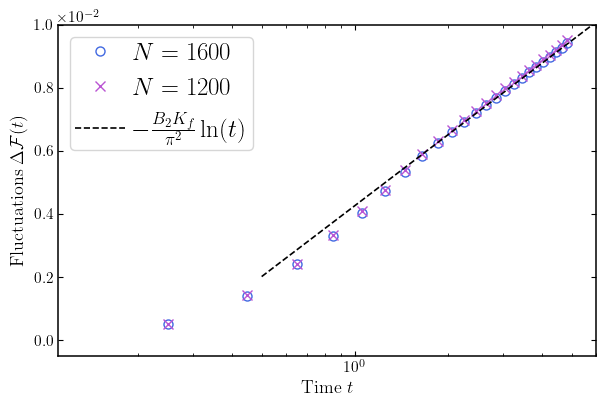

In [109]:
figure_6_paper()

In [57]:

def figure_7_paper(): 
    
    
    df02 = pd.read_csv(data_quench_dir / "NNN/quench_NN_ctr-N1000_FillingFraction0.2_t20.0_V0.7.csv")
    df06 = pd.read_csv(data_quench_dir / "NNN/quench_NN_ctr-N1000_FillingFraction0.6_t20.0_V0.7.csv")
    df044 = pd.read_csv(data_quench_dir / "NNN/quench_NN_ctr-N1000_FillingFraction0.44_t20.0_V0.7.csv")

    times02 = df02["Time"].values
    Fluctuations02 = df02["Variance"].values

    times06 = df06["Time"].values
    Fluctuations06 = df06["Variance"].values

    times044 = df044["Time"].values
    Fluctuations044 = df044["Variance"].values

    filling02 = 200 / 1000
    filling06 = 600 / 1000
    filling044 = 440 / 1000
    t_0 = 1.0 
    t_2 = 0.0
    V_i = 0.7
    V_f = 0.5
    
    def compute_LL_parameter(filling, V, t_0, t_2):
        fermi_velocity = 2 * t_0 * np.sin(np.pi * filling) + 4 * t_2 * np.sin(2 * np.pi * filling)
        numerator = fermi_velocity 
        denominator = fermi_velocity + (2* V / np.pi) * (1 - np.cos(2 * np.pi * filling))
        return np.sqrt(numerator / denominator)

    def compute_LL_sound_velocity(filling, V, t_0, t_2):
        fermi_velocity = 2 * t_0 * np.sin(np.pi * filling) + 4 * t_2 * np.sin(2 * np.pi * filling)
        first_term = fermi_velocity + (V / np.pi) * np.cos(2 * np.pi * filling)
        second_term = fermi_velocity + (V / np.pi) * (2 - np.cos(2 * np.pi * filling))
        return np.sqrt(first_term * second_term)
    


    K_i_02 = compute_LL_parameter(filling02, V_i, t_0, t_2)
    K_f_02 = compute_LL_parameter(filling02, V_f, t_0, t_2)
    #u_f = compute_LL_sound_velocity(filling, V_f, t_0, t_2)

    K_i_06 = compute_LL_parameter(filling06, V_i, t_0, t_2)
    K_f_06 = compute_LL_parameter(filling06, V_f, t_0, t_2)

    K_i_044 = compute_LL_parameter(filling044, V_i, t_0, t_2)
    K_f_044 = compute_LL_parameter(filling044, V_f, t_0, t_2)        

    print(f"Initial LL parameter: {K_i_02:.5f}")
    print(f"Final LL paramter: {K_f_02:.5f}")
    #print(f"Final sound velocity: {u_f_02:.5f}")

    B_param02 = 0.5 * (K_i_02**2 - K_f_02**2) / (K_i_02 * K_f_02)
    m_theory02 = - B_param02 * K_f_02 / ( np.pi**2) 

    B_param06 = 0.5 * (K_i_06**2 - K_f_06**2) / (K_i_06 * K_f_06)
    m_theory06 = - B_param06 * K_f_06 / ( np.pi**2) 

    B_param044 = 0.5 * (K_i_044**2 - K_f_044**2) / (K_i_044 * K_f_044)
    m_theory044 = - B_param044 * K_f_044 / ( np.pi**2)


    Fluctuations02 = Fluctuations02 - Fluctuations02[0]  
    Fluctuations02 = Fluctuations02[1:]
    times02 = times02[1:]

    Fluctuations06 = Fluctuations06 - Fluctuations06[0]
    Fluctuations06 = Fluctuations06[1:]
    times06 = times06[1:]

    Fluctuations044 = Fluctuations044 - Fluctuations044[0]
    Fluctuations044 = Fluctuations044[1:]
    times044 = times044[1:]

    # --- perform fit ---
    mask02 = (times02 >= 2.0) & (times02 <= 3.0)
    times_fit02 = times02[mask02]
    Fluctuations02_fit = Fluctuations02[mask02]
    x_data02 = np.log(times_fit02)
    y_data02 = Fluctuations02_fit
    slope, intercept02, r_value, p_value, std_err = linregress(x_data02, y_data02)

    mask06 = (times06 >= 2.0) & (times06 <= 3.0)
    times_fit06 = times06[mask02]
    Fluctuations06_fit = Fluctuations06[mask06]
    x_data06 = np.log(times_fit06)
    y_data06 = Fluctuations06_fit
    slope, intercept06, r_value, p_value, std_err = linregress(x_data06, y_data06)

    mask044 = (times044 >= 2.0) & (times044 <= 3.0)
    times_fit044 = times044[mask044]
    Fluctuations044_fit = Fluctuations044[mask044]
    x_data044 = np.log(times_fit044)
    y_data044 = Fluctuations044_fit
    slope, intercept044, r_value, p_value, std_err = linregress(x_data044, y_data044)
    
    #print(f"Fit Results: slope = {slope:.6f}, intercept = {intercept:.6f}, R-squared = {r_value**2:.6f}")
    #print(f"m_theory:  {m_theory:.6f}, m_fit: {slope:.6f}, error_percentage: {abs((slope - m_theory)/m_theory)*100:.2f}%")
    
    t_line = np.linspace(0.5, 7, 200)
    # fit_curve = slope * np.log(t_line) + intercept
    theory_curve02 = m_theory02 * np.log(t_line) + intercept02
    theory_curve06 = m_theory06 * np.log(t_line) + intercept06
    theory_curve044 = m_theory044 * np.log(t_line) + intercept044

    # --- Plotting ---
    fig = plt.figure(figsize=(8, 5))
    spec = gridspec.GridSpec(nrows=1, ncols=1)
    ax = fig.add_subplot(spec[0, 0])

    # Plot data using open markers and no connecting lines to mimic Fig 4
    # The 'markevery' parameter prevents the markers from clustering too heavily if you have many data points
    m_spacing = 5
    
    l1, = ax.semilogx(times02, Fluctuations02, color='royalblue', marker='p', markerfacecolor= 'none',
                          linestyle='None', markevery=m_spacing, label=r"$n=0.2 = \frac{200}{1000}$")
    l2, = ax.semilogx(times06, Fluctuations06, color='orchid', marker='s', markerfacecolor= 'none',
                              linestyle='None', markevery=m_spacing, label=r"$n = 0.6 = \frac{600}{1000}$")
    l3, = ax.semilogx(times06, Fluctuations044, color='purple', marker='o', markerfacecolor= 'none',
                              linestyle='None', markevery=m_spacing, label=r"$n = 0.44 = \frac{440}{1000}$")
    
    # Plot theory as a dashed black line, similar to the reference lines in the paper
    l6, = ax.semilogx(t_line, theory_curve02, color='black', linestyle='--', linewidth=1.0)
    l7, = ax.semilogx(t_line, theory_curve06, color='black', linestyle=':', linewidth = 1.0)
    l8, = ax.semilogx(t_line, theory_curve044, color='black', linestyle='-', linewidth = 1.0)

    # Axes and grid styling
    ax.set_xlabel(r"time $t$", fontsize=16)
    ax.set_ylabel(r"$\Delta \mathcal{F}(t)$", fontsize=16)
    ax.tick_params(axis='both', which='major', direction='in', labelsize=14)
    ax.tick_params(axis='both', which='minor', direction='in')
    # ax.set_xlim(0.4, 5.5)
    # ax.set_ylim(0.0024, 0.0125)
    
    # Keeping grid subtle
    ax.grid(True, which="major", linestyle='--', alpha=0.4)
    ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0), useMathText=True)
    ax.yaxis.get_offset_text().set_fontsize(14)
    
    # Legend
    leg = ax.legend(handles=[l1, l2, l3], fontsize=20, loc='best', frameon=True, edgecolor= 'lightgray')

    # --- Adding the Annotation Arrow ---
    target_x = 0.7
    target_y = intercept02 - 0.0015
    
    # Adjust xytext to move the starting point of the text/arrow. 
    # Here it places the text slightly to the left (0.6) and up (+0.003) from the line.
    


    plt.tight_layout()
    plt.savefig(plot_dir / "figure_7.pdf", dpi=300)

    plt.show()

Initial LL parameter: 0.89019
Final LL paramter: 0.91782


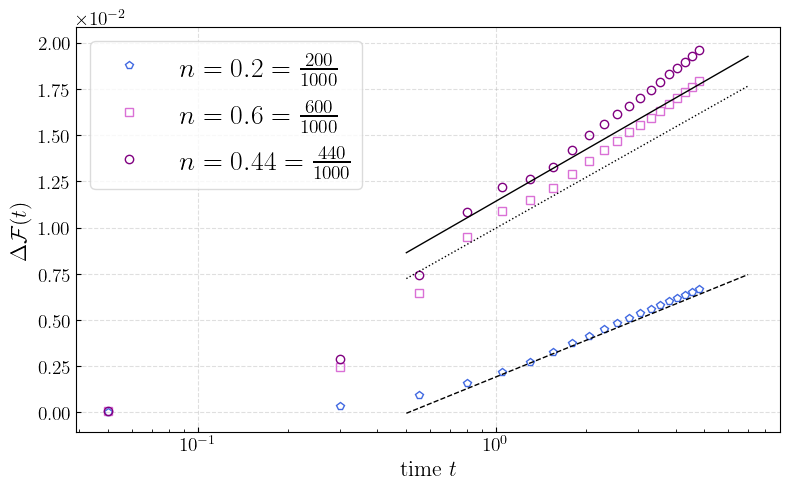

In [58]:
figure_7_paper()

OBC, V=0   E0 values: [-7.3533501  -7.33901892 -7.32712365 -7.31738883 -7.30962618 -7.3037045
 -7.29953323 -7.29705292 -7.29622981 -7.29705292 -7.29953323 -7.3037045
 -7.30962618 -7.31738883 -7.32712365 -7.33901892 -7.3533501 ]
OBC, V=1.0 E0 values: [-8.71603008 -8.70643913 -8.69827147 -8.6914597  -8.68595131 -8.68170606
 -8.67869416 -8.67689504 -8.67629666 -8.67689504 -8.67869416 -8.68170606
 -8.68595131 -8.6914597  -8.69827147 -8.70643913 -8.71603008]
PBC, V=0   E0 values: [-7.46410162 -7.46410162 -7.46410162 -7.46410162 -7.46410162 -7.46410162
 -7.46410162 -7.46410162 -7.46410162 -7.46410162 -7.46410162 -7.46410162
 -7.46410162 -7.46410162 -7.46410162 -7.46410162 -7.46410162]
PBC, V=1.0 E0 values: [-8.86047931 -8.8598449  -8.85931566 -8.85888185 -8.85853597 -8.85827235
 -8.85808686 -8.85797666 -8.85794011 -8.85797666 -8.85808686 -8.85827235
 -8.85853597 -8.85888185 -8.85931566 -8.8598449  -8.86047931]


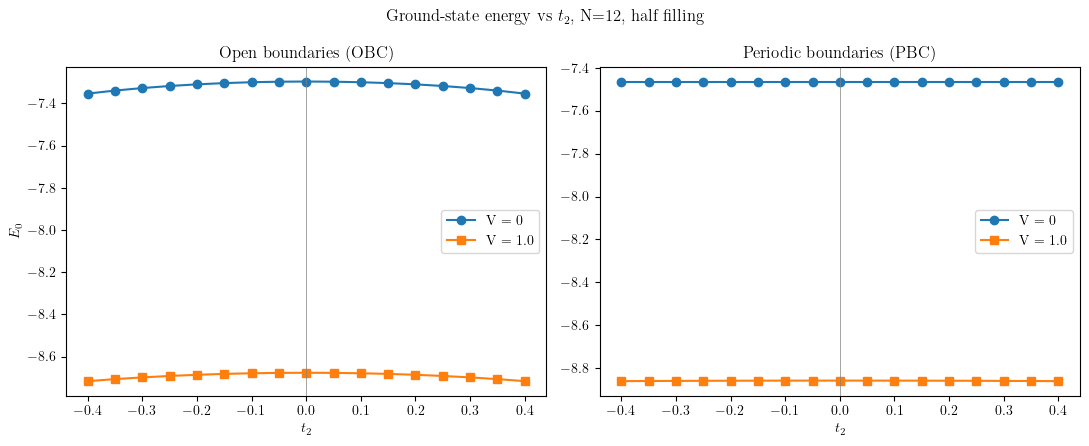

In [50]:
"""
Exact diagonalization of the spinless fermion chain
    H = -t0 sum_i (c_i^dag c_{i+1} + h.c.)
        -t2 sum_i (c_i^dag c_{i+2} + h.c.)
        + V  sum_i (n_i - 1/2)(n_{i+1} - 1/2)
on a small open chain, at half filling, to test how the ground-state
energy depends on t2.

Basis: occupation-number states represented as Python ints (bit b = site b).
Operators: built directly in the fixed-particle-number sector via bit tricks,
no need to build full creation/annihilation matrices on the full 2^N space.
"""

import numpy as np
from itertools import combinations
import matplotlib.pyplot as plt


def build_basis(N, Npart):
    """All occupation states with exactly Npart particles on N sites."""
    basis = []
    for occ in combinations(range(N), Npart):
        state = 0
        for site in occ:
            state |= (1 << site)
        basis.append(state)
    basis.sort()
    index = {state: i for i, state in enumerate(basis)}
    return basis, index


def hop_element(state, i, j):
    """
    Returns (new_state, sign) for c_i^dagger c_j acting on `state`,
    or None if the matrix element vanishes.
    Convention: |n_0,...,n_{N-1}> = (c_0^dag)^{n_0} (c_1^dag)^{n_1} ... |vac>,
    bit b of `state` is n_b.
    """
    if not (state >> j) & 1:
        return None                      # site j empty: c_j kills the state
    if i != j and (state >> i) & 1:
        return None                      # site i already occupied: Pauli blocking
    lo, hi = (i, j) if i < j else (j, i)
    mask = ((1 << hi) - 1) ^ ((1 << (lo + 1)) - 1)   # bits strictly between lo and hi
    sign = -1 if bin(state & mask).count("1") % 2 else 1
    new_state = (state & ~(1 << j)) | (1 << i)
    return new_state, sign


def bond_list(N, reach, pbc):
    """(i, j=i+reach) bonds for a given hop length. With pbc=True, also
    includes the `reach` wrap-around bonds closing the ring."""
    bonds = [(i, i + reach) for i in range(N - reach)]
    if pbc:
        bonds += [(i, i + reach - N) for i in range(N - reach, N)]
    return bonds


def build_hamiltonian(N, t0, t2, V, basis, index, pbc=False):
    dim = len(basis)
    H = np.zeros((dim, dim))

    for col, state in enumerate(basis):
        # --- hopping terms: -t0 (c_i^dag c_{i+1} + h.c.) and -t2 (c_i^dag c_{i+2} + h.c.)
        for (t, reach) in [(t0, 1), (t2, 2)]:
            if t == 0.0:
                continue
            for (i, j) in bond_list(N, reach, pbc):
                for (a, b) in [(i, j), (j, i)]:            # c_a^dag c_b  (both directions -> h.c.)
                    res = hop_element(state, a, b)
                    if res is not None:
                        new_state, sign = res
                        row = index[new_state]
                        H[row, col] += -t * sign

        # --- interaction: V sum_i (n_i - 1/2)(n_{i+1} - 1/2)   (diagonal)
        if V != 0.0:
            diag = 0.0
            for (i, j) in bond_list(N, 1, pbc):
                ni = (state >> i) & 1
                nj = (state >> j) & 1
                diag += V * (ni - 0.5) * (nj - 0.5)
            H[col, col] += diag

    return H


def ground_energy(N, t0, t2, V, pbc=False):
    Npart = N // 2  # half filling (N even)
    basis, index = build_basis(N, Npart)
    H = build_hamiltonian(N, t0, t2, V, basis, index, pbc=pbc)
    evals = np.linalg.eigvalsh(H)
    return evals[0]


if __name__ == "__main__":
    N = 12
    t0 = 1.0
    t2_values = np.linspace(-0.4, 0.4, 17)

    E_V0_obc = [ground_energy(N, t0, t2, V=0.0, pbc=False) for t2 in t2_values]
    E_Vnz_obc = [ground_energy(N, t0, t2, V=1.0, pbc=False) for t2 in t2_values]
    E_V0_pbc = [ground_energy(N, t0, t2, V=0.0, pbc=True) for t2 in t2_values]
    E_Vnz_pbc = [ground_energy(N, t0, t2, V=1.0, pbc=True) for t2 in t2_values]

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True)

    axes[0].plot(t2_values, E_V0_obc, "o-", label="V = 0")
    axes[0].plot(t2_values, E_Vnz_obc, "s-", label="V = 1.0")
    axes[0].set_title("Open boundaries (OBC)")

    axes[1].plot(t2_values, E_V0_pbc, "o-", label="V = 0")
    axes[1].plot(t2_values, E_Vnz_pbc, "s-", label="V = 1.0")
    axes[1].set_title("Periodic boundaries (PBC)")

    for ax in axes:
        ax.axvline(0, color="gray", lw=0.5)
        ax.set_xlabel(r"$t_2$")
        ax.legend()
    axes[0].set_ylabel(r"$E_0$")

    fig.suptitle(f"Ground-state energy vs $t_2$, N={N}, half filling")
    fig.tight_layout()
    #fig.savefig("/mnt/user-data/outputs/E0_vs_t2.png", dpi=150)

    print("OBC, V=0   E0 values:", np.array(E_V0_obc))
    print("OBC, V=1.0 E0 values:", np.array(E_Vnz_obc))
    print("PBC, V=0   E0 values:", np.array(E_V0_pbc))
    print("PBC, V=1.0 E0 values:", np.array(E_Vnz_pbc))

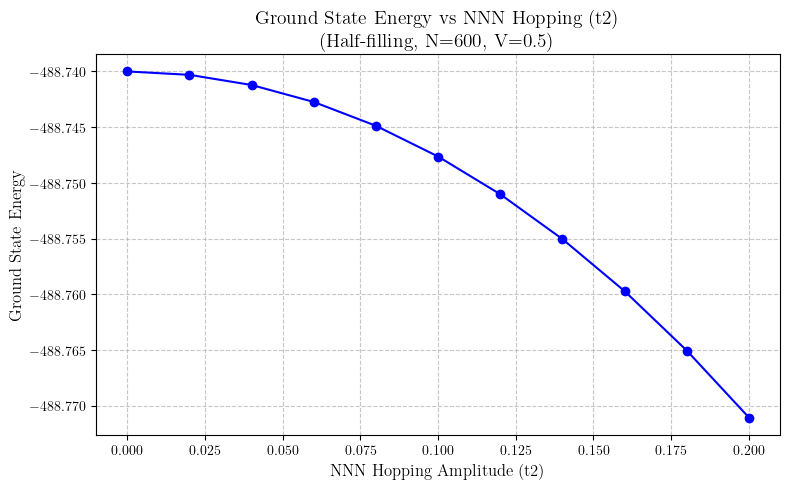

In [61]:
import pandas as pd
import matplotlib.pyplot as plt

# Update this path if your Jupyter notebook is in a different directory relative to the data
df = pd.read_csv("/home/giuliano-artale/Workspace/SSH-Analysis/data/ground_state_sweep/energy_vs_t2_N600_V0.5.csv")

# Set up the plot style for a clean, professional look
plt.figure(figsize=(8, 5))
plt.plot(df['t2'], df['GroundEnergy'], marker='o', linestyle='-', color='b', markersize=6)

# Formatting
plt.title('Ground State Energy vs NNN Hopping (t2)\n(Half-filling, N=600, V=0.5)', fontsize=14)
plt.xlabel('NNN Hopping Amplitude (t2)', fontsize=12)
plt.ylabel('Ground State Energy', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

# Adjust y-axis to not use scientific notation for small variations, 
# making the boundary effect offset clearer
plt.ticklabel_format(useOffset=False, style='plain', axis='y')

plt.tight_layout()
plt.show()

In [228]:
def compute_LL_parameter(filling, V, t_0, t_2):
    fermi_velocity = 2 * t_0 * np.sin(np.pi * filling) + 4 * t_2 * np.sin(2 * np.pi * filling)
    numerator = fermi_velocity 
    denominator = fermi_velocity + (2* V / np.pi) * (1 - np.cos(2 * np.pi * filling))
    return np.sqrt(numerator / denominator)

def compute_LL_sound_velocity(filling, V, t_0, t_2):
    fermi_velocity = 2 * t_0 * np.sin(np.pi * filling) + 4 * t_2 * np.sin(2 * np.pi * filling)
    first_term = fermi_velocity + (V / np.pi) * np.cos(2 * np.pi * filling)
    second_term = fermi_velocity + (V / np.pi) * (2 - np.cos(2 * np.pi * filling))
    return np.sqrt(first_term * second_term)



def figure_X_paper(): 


    # Setting the figures
    fig = plt.figure(figsize=(6, 8))
    spec = gridspec.GridSpec(nrows=2, ncols=1)
    ax1 = fig.add_subplot(spec[0 , 0])
    ax2 = fig.add_subplot(spec[1 , 0])

    # --- ax1 ---
    
    df_1 = pd.read_csv(data_quench_dir / "NNN/quench_NN_ctr-N1200_FillingFraction0.25_t20.0_V0.7.csv")

    times_1 = df_1["Time"].values
    Fluctuations_1 = df_1["Variance"].values

    n_1 = 0.25
    t_2_1 = 0
    V_i = 0.7
    V_f = 0.5
    t_0 = 1
    K_i_1 = compute_LL_parameter(n_1, V_i, t_0, t_2_1)
    K_f_1 = compute_LL_parameter(n_1, V_f, t_0, t_2_1)

    B_param_1 = 0.5 * (K_i_1**2 - K_f_1**2) / (K_i_1 * K_f_1)
    m_theory_1 = - B_param_1 * K_f_1 / ( np.pi**2) 

    Fluctuations_1 = Fluctuations_1 - Fluctuations_1[0]  
    Fluctuations_1 = Fluctuations_1[1:]
    times_1 = times_1[1:]

    # --- perform fit ---
    mask = (times_1 >= 2.0) & (times_1 <= 5.0)
    times_fit = times_1[mask]
    Fluctuations_fit_1 = Fluctuations_1[mask]
    x_data_1 = np.log(times_fit)
    y_data_1 = Fluctuations_fit_1
    slope, intercept_1, r_value, p_value, std_err = linregress(x_data_1, y_data_1)
    
    t_line_1 = np.linspace(0.5, 7, 200)
    # fit_curve = slope * np.log(t_line) + intercept
    theory_curve_1 = m_theory_1 * np.log(t_line_1) + intercept_1 

    m_spacing = 5
    m_size = 6.0
    m_ew = 1.2

    # 1. Provide an explicit label to eliminate MatplotlibDeprecationWarning
    l_1_1, = ax1.semilogx(times_1, Fluctuations_1, color='royalblue', marker='s', 
                      markerfacecolor='none', linestyle='None', 
                      markevery=m_spacing, markersize=m_size, 
                      markeredgewidth=m_ew, label=r"Data ($n= 0.25$)")
    l_1_2, = ax1.semilogx(t_line_1, theory_curve_1, color='black', linestyle='--', 
                        linewidth=1.2, label=r"$-\frac{B_2 K_f}{\pi^2} \ln(t)$")

    # Axes and grid styling
    ax1.set_xlabel(r"time $t$", fontsize=16)
    ax1.set_ylabel(r"Fluctuations $\Delta \mathcal{F}(t)$", fontsize=16)
    ax1.tick_params(axis='both', which='major', direction='in', labelsize=14)
    ax1.tick_params(axis='both', which='minor', direction='in')
    
    # Keeping grid subtle
    ax1.grid(False)
    ax1.ticklabel_format(style='sci', axis='y', scilimits=(0,0), useMathText=True)
    ax1.yaxis.get_offset_text().set_fontsize(14)
    
    # Legend
    leg = ax1.legend(handles=[l_1_1, l_1_2], fontsize=16, loc='best', frameon=True, edgecolor= 'lightgray')

    # --- ax2 --- 

    
    df_2 = pd.read_csv(data_quench_dir / "NNN/quench_NN_ctr-N1600_t20.0_V0.7.csv")

    times_2 = df_2["Time"].values
    Fluctuations_2 = df_2["Variance"].values

    # --- Param Bethe Ansatz---
    mu_i = np.arccos(V_i / 2)
    mu_f = np.arccos(V_f / 2)

    K_i_2 = np.pi / (2 * (np.pi - mu_i))
    K_f_2 = np.pi / (2 * (np.pi - mu_f))

    B_param_2 = 0.5 * (K_i_2**2 - K_f_2**2) / (K_i_2 * K_f_2)
    m_theory_2 = - B_param_2 * K_f_2 / ( np.pi**2) 

    Fluctuations_2 = Fluctuations_2 - Fluctuations_2[0]  
    Fluctuations_2 = Fluctuations_2[1:]
    times_2 = times_2[1:]

    # --- perform fit ---
    mask = (times_2 >= 2.0) & (times_2 <= 5.0)
    times_fit = times_2[mask]
    Fluctuations_fit_2 = Fluctuations_2[mask]
    x_data_2 = np.log(times_fit)
    y_data_2 = Fluctuations_fit_2
    slope, intercept_2, r_value, p_value, std_err = linregress(x_data_2, y_data_2)
    
    t_line_2 = np.linspace(0.5, 7, 200)
    theory_curve_2 = m_theory_2 * np.log(t_line_2) + intercept_2 

    m_spacing = 5
    m_size = 6.0
    m_ew = 1.2

    # 1. Provide an explicit label to eliminate MatplotlibDeprecationWarning
    l_2_1, = ax2.semilogx(times_2, Fluctuations_2, color='royalblue', marker='s', 
                      markerfacecolor='none', linestyle='None', 
                      markevery=m_spacing, markersize=m_size, 
                      markeredgewidth=m_ew, label=r"Data ($n=0.5$)")
    l_2_2, = ax2.semilogx(t_line_2, theory_curve_2, color='black', linestyle='--', 
                        linewidth=1.2, label=r"$-\frac{B_2 K_f}{\pi^2} \ln(t)$")

    # Axes and grid styling
    ax2.set_xlabel(r"time $t$", fontsize=16)
    ax2.set_ylabel(r"Fluctuations $\Delta \mathcal{F}(t)$", fontsize=16)
    ax2.tick_params(axis='both', which='major', direction='in', labelsize=14)
    ax2.tick_params(axis='both', which='minor', direction='in')
    
    # Keeping grid subtle
    ax2.grid(False)
    ax2.ticklabel_format(style='sci', axis='y', scilimits=(0,0), useMathText=True)
    ax2.yaxis.get_offset_text().set_fontsize(14)
    
    # Legend
    leg1 = ax2.legend(handles=[l_2_1, l_2_2], fontsize=16, loc='best', frameon=True, edgecolor= 'lightgray')




    plt.tight_layout()
    plt.savefig(plot_dir / "figure_X.pdf", dpi=300)

    plt.show()

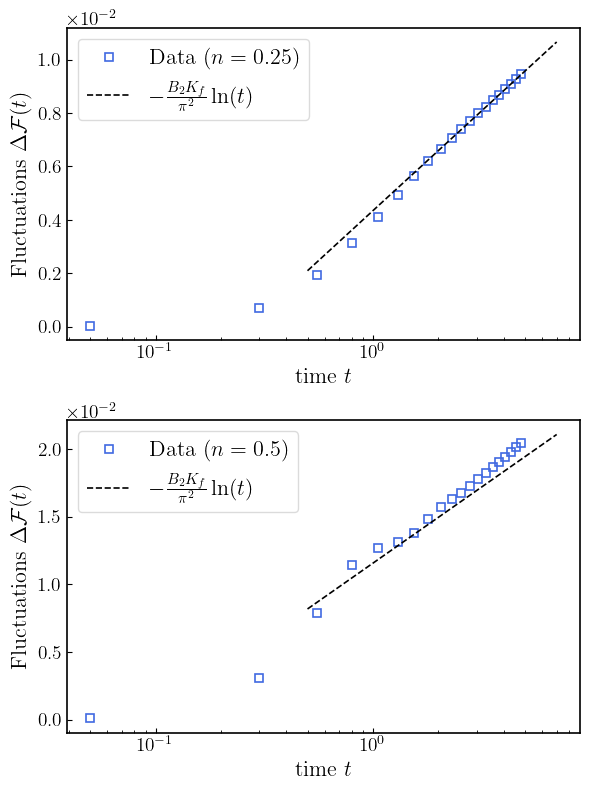

In [229]:
figure_X_paper()

In [13]:
def compute_LL_parameter(filling, V, t_0, t_2):
    fermi_velocity = 2 * t_0 * np.sin(np.pi * filling) + 4 * t_2 * np.sin(2 * np.pi * filling)
    numerator = fermi_velocity 
    denominator = fermi_velocity + (2* V / np.pi) * (1 - np.cos(2 * np.pi * filling))
    return np.sqrt(numerator / denominator)

def compute_LL_sound_velocity(filling, V, t_0, t_2):
    fermi_velocity = 2 * t_0 * np.sin(np.pi * filling) + 4 * t_2 * np.sin(2 * np.pi * filling)
    first_term = fermi_velocity + (V / np.pi) * np.cos(2 * np.pi * filling)
    second_term = fermi_velocity + (V / np.pi) * (2 - np.cos(2 * np.pi * filling))
    return np.sqrt(first_term * second_term)


from matplotlib.ticker import MaxNLocator

APS_RC = {
    "font.family": "serif",
    "mathtext.fontset": "cm",
    "font.size": 9,
    "axes.labelsize": 10,
    "legend.fontsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    # ticks on all four sides, pointing inward, with minor ticks
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "xtick.minor.visible": True,
    "ytick.minor.visible": True,
    # embed TrueType fonts (Type 42) instead of Type 3
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
}

def figure_X1_paper(): 
    with plt.rc_context(APS_RC):

        # Setting the figures
        fig_h = 4.2
        fig = plt.figure(figsize=(3.4, fig_h))
        spec = gridspec.GridSpec(nrows=3, ncols=1, hspace=0, left=0.18, right=0.97, top=0.985, bottom=0.55 / fig_h)
        ax1 = fig.add_subplot(spec[0, 0])
        ax2 = fig.add_subplot(spec[1, 0], sharex=ax1)
        ax3 = fig.add_subplot(spec[2, 0], sharex=ax1)

        m_spacing = 5
        m_size = 4.5
        m_ew = 1.0
        theory_label = r"$-\frac{B_2 K_f}{\pi^2}\,\ln t$"

        # ----------------------------------------------- ax1 

        df_a = pd.read_csv(data_quench_dir / "NNN/quench_NN_ctr-N1200_FillingFraction0.25_t20.0_V0.7.csv")

        times_a = df_a["Time"].values
        Fluctuations_a = df_a["Variance"].values

        n_a = 0.25
        t_2_a = 0
        V_i_a = 0.7
        V_f_a = 0.5
        t_0_a = 1
        K_i_a = compute_LL_parameter(n_a, V_i_a, t_0_a, t_2_a)
        K_f_a = compute_LL_parameter(n_a, V_f_a, t_0_a, t_2_a)

        B_param_a = 0.5 * (K_i_a**2 - K_f_a**2) / (K_i_a * K_f_a)
        m_theory_a = - B_param_a * K_f_a / ( np.pi**2) 

        Fluctuations_a = Fluctuations_a - Fluctuations_a[0]  
        Fluctuations_a = Fluctuations_a[1:]
        times_a = times_a[1:]

        # --- perform fit ---
        mask_a = (times_a >= 2.0) & (times_a <= 3.0)
        times_fit_a = times_a[mask_a]
        Fluctuations_fit_a = Fluctuations_a[mask_a]
        x_data_a = np.log(times_fit_a)
        y_data_a = Fluctuations_fit_a
        slope, intercept_a, r_value, p_value, std_err = linregress(x_data_a, y_data_a)
        intercept_a = np.mean(y_data_a - m_theory_a * np.log(times_fit_a))

        t_line_a = np.linspace(0.5, 7, 200)
        # fit_curve = slope * np.log(t_line) + intercept
        theory_curve_a = m_theory_a * np.log(t_line_a) + intercept_a 


        # 1. Provide an explicit label to eliminate MatplotlibDeprecationWarning
        l_a_1, = ax1.semilogx(times_a, Fluctuations_a*100, color='royalblue', marker='s', 
                            markerfacecolor='none', linestyle='None', 
                            markersize=m_size, markevery = m_spacing,
                            markeredgewidth=m_ew, label=r"Data")
        l_a_2, = ax1.semilogx(t_line_a, theory_curve_a*100, color='black', linestyle='--', 
                            linewidth=1.2, label=theory_label)

        ax1.legend(handles=[l_a_1, l_a_2], loc='upper left', frameon=True, edgecolor = 'lightgray')
        ax1.text(0.32, 0.32, r"$n= \frac{N_p}{N}=1/4$", transform=ax1.transAxes, ha='right', va ='bottom')
        ax1.text(0.96, 0.10, r"(a)", transform=ax1.transAxes, ha='right', va ='bottom', weight= 'bold')
        
        # -------------------------------------------- ax2
        df_b = pd.read_csv(data_quench_dir / "NNN/quench_NN_ctr-N1200_FillingFraction0.3333333333333333_t20.0_Vi0.7_Vf0.5.csv")

        times_b = df_b["Time"].values
        Fluctuations_b = df_b["Variance"].values

        n_b = 400/1200
        t_2_b = 0
        V_i_b = 0.7
        V_f_b = 0.5
        t_0_b = 1
        K_i_b = compute_LL_parameter(n_b, V_i_b, t_0_b, t_2_b)
        K_f_b = compute_LL_parameter(n_b, V_f_b, t_0_b, t_2_b)

        B_param_b = 0.5 * (K_i_b**2 - K_f_b**2) / (K_i_b * K_f_b)
        m_theory_b = - B_param_b * K_f_b / ( np.pi**2) 

        Fluctuations_b = Fluctuations_b - Fluctuations_b[0]  
        Fluctuations_b = Fluctuations_b[1:]
        times_b = times_b[1:]

        # --- perform fit ---
        mask_b = (times_b >= 2.0) & (times_b <= 3.0)
        times_fit_b = times_b[mask_b]
        Fluctuations_fit_b = Fluctuations_b[mask_b]
        x_data_b = np.log(times_fit_b)
        y_data_b = Fluctuations_fit_b
        slope, intercept_b, r_value, p_value, std_err = linregress(x_data_b, y_data_b)
        intercept_b = np.mean(y_data_b - m_theory_b * np.log(times_fit_b))

        t_line_b = np.linspace(0.5, 7, 200)
        theory_curve_b = m_theory_b * np.log(t_line_b) + intercept_b


        l_b_1, = ax2.semilogx(times_b, Fluctuations_b*100, color='royalblue', marker='s', 
                            markerfacecolor='none', linestyle='None', 
                            markersize=m_size,
                            markeredgewidth=m_ew)
        l_b_2, = ax2.semilogx(t_line_b, theory_curve_b*100, color='black', linestyle='--', 
                            linewidth=1.2)

        ax2.text(0.32, 0.5, r"$n= \frac{N_p}{N}=1/3$", transform=ax2.transAxes, ha='right', va ='bottom')
        ax2.text(0.96, 0.10, r"(b)", transform=ax2.transAxes, ha='right', va ='bottom', weight= 'bold')


        # ------------------------------------------------------ ax3 


        df_c = pd.read_csv(data_quench_dir / "NNN/quench_NN_ctr-N1200_FillingFraction0.5_t20.0_Vi0.7_Vf0.5.csv")

        times_c = df_c["Time"].values
        Fluctuations_c = df_c["Variance"].values

        # --- Param Bethe Ansatz---
        V_i_c = 0.7
        V_f_c = 0.5
        mu_i = np.arccos(V_i_c / 2)
        mu_f = np.arccos(V_f_c / 2)

        K_i_c = np.pi / (2 * (np.pi - mu_i))
        K_f_c = np.pi / (2 * (np.pi - mu_f))

        B_param_c = 0.5 * (K_i_c**2 - K_f_c**2) / (K_i_c * K_f_c)
        m_theory_c = - B_param_c * K_f_c / ( np.pi**2) 

        Fluctuations_c = Fluctuations_c - Fluctuations_c[0]  
        Fluctuations_c = Fluctuations_c[1:]
        times_c = times_c[1:]

        # --- perform fit ---
        mask_c = (times_c >= 2.0) & (times_c <= 3.0)
        times_fit_c = times_c[mask_c]
        Fluctuations_fit_c = Fluctuations_c[mask_c]
        x_data_c = np.log(times_fit_c)
        y_data_c = Fluctuations_fit_c
        slope, intercept_c, r_value, p_value, std_err = linregress(x_data_c, y_data_c)
        intercept_c = np.mean(y_data_c - m_theory_c * np.log(times_fit_c))


        t_line_c = np.linspace(0.5, 7, 200)
        theory_curve_c = m_theory_c * np.log(t_line_c) + intercept_c 

        # 1. Provide an explicit label to eliminate MatplotlibDeprecationWarning
        l_c_1, = ax3.semilogx(times_c, Fluctuations_c * 100, color='royalblue', marker='s', 
                            markerfacecolor='none', linestyle='None', 
                            markersize=m_size, 
                            markeredgewidth=m_ew)
        l_c_2, = ax3.semilogx(t_line_c, theory_curve_c *100, color='black', linestyle='--', 
                            linewidth=1.2)
        ax3.text(0.32, 0.5, r"$n= \frac{N_p}{N}=1/2$", transform=ax3.transAxes, ha='right', va ='bottom')
        ax3.text(0.96, 0.10, r"(c)", transform=ax3.transAxes, ha='right', va ='bottom', weight= 'bold')

        #------------------------------- shared stuff
        ax1.set_xlim(0.2, 6)
        ax3.set_xlabel(r"Time $t$")
        fig.supylabel(r"$\Delta\mathcal{F}(t)\times 10^{2}$", x=0.03, y=0.56, fontsize=10)

        for ax in (ax1, ax2, ax3):
            ax.yaxis.set_major_locator(MaxNLocator(nbins=4))

        fig.canvas.draw()  # make sure autoscaling and limits are settled

        for ax in (ax2, ax3):
            ymin, ymax = ax.get_ylim()
            margin = 0.06 * (ymax - ymin)
            ticks = [t for t in ax.get_yticks() if ymin <= t <= ymax - margin]
            ax.set_yticks(ticks)
        ax1.legend(fontsize = 10)
        plt.savefig(plot_dir / "figure_2.pdf", dpi=300)

        plt.show()

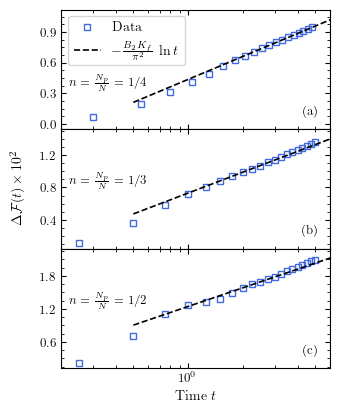

In [14]:
figure_X1_paper()

In [ ]:
def compute_LL_parameter(filling, V, t_0, t_2):
    fermi_velocity = 2 * t_0 * np.sin(np.pi * filling) + 4 * t_2 * np.sin(2 * np.pi * filling)
    numerator = fermi_velocity 
    denominator = fermi_velocity + (2* V / np.pi) * (1 - np.cos(2 * np.pi * filling))
    return np.sqrt(numerator / denominator)

def compute_LL_sound_velocity(filling, V, t_0, t_2):
    fermi_velocity = 2 * t_0 * np.sin(np.pi * filling) + 4 * t_2 * np.sin(2 * np.pi * filling)
    first_term = fermi_velocity + (V / np.pi) * np.cos(2 * np.pi * filling)
    second_term = fermi_velocity + (V / np.pi) * (2 - np.cos(2 * np.pi * filling))
    return np.sqrt(first_term * second_term)


from matplotlib.ticker import MaxNLocator

APS_RC = {
    "font.family": "serif",
    "mathtext.fontset": "cm",
    "font.size": 9,
    "axes.labelsize": 10,
    "legend.fontsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    # ticks on all four sides, pointing inward, with minor ticks
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "xtick.minor.visible": True,
    "ytick.minor.visible": True,
    # embed TrueType fonts (Type 42) instead of Type 3
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
}

def figure_half_filling_comparison_paper(): 
    with plt.rc_context(APS_RC):

        # Setting the figures
        fig_h = 4.2
        fig = plt.figure(figsize=(3.4, fig_h))
        spec = gridspec.GridSpec(nrows=3, ncols=1, hspace=0, left=0.18, right=0.97, top=0.985, bottom=0.55 / fig_h)
        ax1 = fig.add_subplot(spec[0, 0])
        ax2 = fig.add_subplot(spec[1, 0], sharex=ax1)
        ax3 = fig.add_subplot(spec[2, 0], sharex=ax1)

                # --- Param Bethe Ansatz---
        V_i = 0.7
        V_f = 0.5
        mu_i = np.arccos(V_i / 2)
        mu_f = np.arccos(V_f / 2)

        K_i = np.pi / (2 * (np.pi - mu_i))
        K_f = np.pi / (2 * (np.pi - mu_f))

        B_param = 0.5 * (K_i**2 - K_f**2) / (K_i * K_f)
        m_theory = - B_param * K_f/ ( np.pi**2) 

        m_spacing = 5
        m_size = 4.5
        m_ew = 1.0
        theory_label = r"$-\frac{B_2 K_f}{\pi^2}\,\ln t$"

        # ----------------------------------------------- ax1 

        df_a = pd.read_csv(data_quench_dir / "NNN/quench_NN_ctr-N1200_FillingFraction0.5_t20.0_Vi0.7_Vf0.5_l400.csv")

        times_a = df_a["Time"].values
        Fluctuations_a = df_a["Variance"].values

        Fluctuations_a = Fluctuations_a - Fluctuations_a[0]  
        Fluctuations_a = Fluctuations_a[1:]
        times_a = times_a[1:]
        print("Fluctuations for l = 400: ", Fluctuations_a)


        # --- perform fit ---
        mask_a = (times_a >= 2.0) & (times_a <= 3.0)
        times_fit_a = times_a[mask_a]
        Fluctuations_fit_a = Fluctuations_a[mask_a]
        x_data_a = np.log(times_fit_a)
        y_data_a = Fluctuations_fit_a
        slope, intercept_a, r_value, p_value, std_err = linregress(x_data_a, y_data_a)
        intercept_a = np.mean(y_data_a - m_theory * np.log(times_fit_a))

        t_line_a = np.linspace(0.5, 7, 200)
        # fit_curve = slope * np.log(t_line) + intercept
        theory_curve_a = m_theory * np.log(t_line_a) + intercept_a 


        # 1. Provide an explicit label to eliminate MatplotlibDeprecationWarning
        l_a_1, = ax1.semilogx(times_a, Fluctuations_a*100, color='royalblue', marker='s', 
                            markerfacecolor='none', linestyle='None', 
                            markersize=m_size, 
                            markeredgewidth=m_ew, label=r"Data")
        l_a_2, = ax1.semilogx(t_line_a, theory_curve_a*100, color='black', linestyle='--', 
                            linewidth=1.2, label=theory_label)

        ax1.legend(handles=[l_a_1, l_a_2], loc='upper left', frameon=True, edgecolor = 'lightgray')
        ax1.text(0.32, 0.32, r"$l=400$", transform=ax1.transAxes, ha='right', va ='bottom')
        ax1.text(0.96, 0.10, r"(a)", transform=ax1.transAxes, ha='right', va ='bottom', weight= 'bold')
        
        # -------------------------------------------- ax2
        df_b = pd.read_csv(data_quench_dir / "NNN/quench_NN_ctr-N1200_FillingFraction0.5_t20.0_Vi0.7_Vf0.5_l300.csv")

        times_b = df_b["Time"].values
        Fluctuations_b = df_b["Variance"].values


        Fluctuations_b = Fluctuations_b - Fluctuations_b[0]  
        Fluctuations_b = Fluctuations_b[1:]
        times_b = times_b[1:]
        print("Fluctuations for l = 300: ", Fluctuations_b)

        # --- perform fit ---
        mask_b = (times_b >= 2.0) & (times_b <= 3.0)
        times_fit_b = times_b[mask_b]
        Fluctuations_fit_b = Fluctuations_b[mask_b]
        x_data_b = np.log(times_fit_b)
        y_data_b = Fluctuations_fit_b
        slope, intercept_b, r_value, p_value, std_err = linregress(x_data_b, y_data_b)
        intercept_b = np.mean(y_data_b - m_theory * np.log(times_fit_b))

        t_line_b = np.linspace(0.5, 7, 200)
        theory_curve_b = m_theory * np.log(t_line_b) + intercept_b


        l_b_1, = ax2.semilogx(times_b, Fluctuations_b*100, color='royalblue', marker='s', 
                            markerfacecolor='none', linestyle='None', 
                            markersize=m_size,
                            markeredgewidth=m_ew)
        l_b_2, = ax2.semilogx(t_line_b, theory_curve_b*100, color='black', linestyle='--', 
                            linewidth=1.2)

        ax2.text(0.32, 0.5, r"$l=300$", transform=ax2.transAxes, ha='right', va ='bottom')
        ax2.text(0.96, 0.10, r"(b)", transform=ax2.transAxes, ha='right', va ='bottom', weight= 'bold')


        # ------------------------------------------------------ ax3 


        df_c = pd.read_csv(data_quench_dir / "NNN/quench_NN_ctr-N1200_FillingFraction0.5_t20.0_Vi0.7_Vf0.5.csv")

        times_c = df_c["Time"].values
        Fluctuations_c = df_c["Variance"].values

        Fluctuations_c = Fluctuations_c - Fluctuations_c[0]  
        Fluctuations_c = Fluctuations_c[1:]
        times_c = times_c[1:]
        print("Fluctuations for l = 200: ", Fluctuations_c)

        # --- perform fit ---
        mask_c = (times_c >= 2.0) & (times_c <= 3.0)
        times_fit_c = times_c[mask_c]
        Fluctuations_fit_c = Fluctuations_c[mask_c]
        x_data_c = np.log(times_fit_c)
        y_data_c = Fluctuations_fit_c
        slope, intercept_c, r_value, p_value, std_err = linregress(x_data_c, y_data_c)
        intercept_c = np.mean(y_data_c - m_theory * np.log(times_fit_c))


        t_line_c = np.linspace(0.5, 7, 200)
        theory_curve_c = m_theory * np.log(t_line_c) + intercept_c 

        # 1. Provide an explicit label to eliminate MatplotlibDeprecationWarning
        l_c_1, = ax3.semilogx(times_c, Fluctuations_c * 100, color='royalblue', marker='s', 
                            markerfacecolor='none', linestyle='None', 
                            markersize=m_size, 
                            markeredgewidth=m_ew)
        l_c_2, = ax3.semilogx(t_line_c, theory_curve_c *100, color='black', linestyle='--', 
                            linewidth=1.2)
        ax3.text(0.32, 0.5, r"$l=200$", transform=ax3.transAxes, ha='right', va ='bottom')
        ax3.text(0.96, 0.10, r"(c)", transform=ax3.transAxes, ha='right', va ='bottom', weight= 'bold')

        #------------------------------- shared stuff
        ax1.set_xlim(0.2, 6)
        ax3.set_xlabel(r"Time $t$")
        fig.supylabel(r"$\Delta\mathcal{F}(t)\times 10^{2}$", x=0.03, y=0.56, fontsize=10)

        for ax in (ax1, ax2, ax3):
            ax.yaxis.set_major_locator(MaxNLocator(nbins=4))

        fig.canvas.draw()  # make sure autoscaling and limits are settled

        for ax in (ax2, ax3):
            ymin, ymax = ax.get_ylim()
            margin = 0.06 * (ymax - ymin)
            ticks = [t for t in ax.get_yticks() if ymin <= t <= ymax - margin]
            ax.set_yticks(ticks)
        ax1.legend(fontsize = 10)
        plt.savefig(plot_dir / "figure_2_comp.pdf", dpi=300)

        plt.show()

Fluctuations for l = 400:  [0.00223953 0.00710907 0.01116526 0.01289975 0.01333534 0.01390947
 0.01492095 0.01590242 0.01656398 0.01702422 0.01748682 0.01800189
 0.01850753 0.01895353 0.01934533 0.01971139 0.02006898 0.02042181
 0.02076668 0.02109443]
Fluctuations for l = 300:  [0.00223213 0.00707466 0.01110795 0.01283422 0.01327472 0.01385544
 0.01486624 0.01584015 0.01649346 0.01694994 0.01741362 0.01793093
 0.01843538 0.01887701 0.01926403 0.01962657 0.01998143 0.02033108
 0.02067289 0.02100043]
Fluctuations for l=200:  [0.00221932 0.00703359 0.01103903 0.01275341 0.0131987  0.01379019
 0.01480591 0.01577695 0.01642564 0.01688171 0.0173497  0.01787153
 0.01837704 0.01881707 0.01920367 0.01956917 0.01992893 0.02028239
 0.02062586 0.02095476]


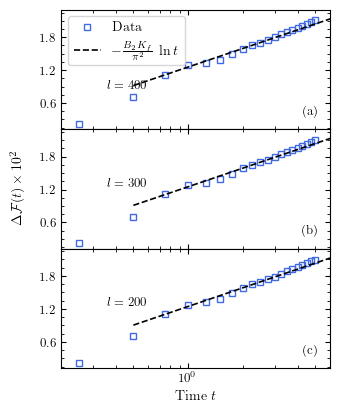

In [9]:
figure_half_filling_comparison_paper()

In [16]:
def compute_LL_parameter(filling, V, t_0, t_2):
    fermi_velocity = 2 * t_0 * np.sin(np.pi * filling) + 4 * t_2 * np.sin(2 * np.pi * filling)
    numerator = fermi_velocity 
    denominator = fermi_velocity + (2* V / np.pi) * (1 - np.cos(2 * np.pi * filling))
    return np.sqrt(numerator / denominator)

def compute_LL_sound_velocity(filling, V, t_0, t_2):
    fermi_velocity = 2 * t_0 * np.sin(np.pi * filling) + 4 * t_2 * np.sin(2 * np.pi * filling)
    first_term = fermi_velocity + (V / np.pi) * np.cos(2 * np.pi * filling)
    second_term = fermi_velocity + (V / np.pi) * (2 - np.cos(2 * np.pi * filling))
    return np.sqrt(first_term * second_term)


from matplotlib.ticker import MaxNLocator

APS_RC = {
    "font.family": "serif",
    "mathtext.fontset": "cm",
    "font.size": 9,
    "axes.labelsize": 10,
    "legend.fontsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    # ticks on all four sides, pointing inward, with minor ticks
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "xtick.minor.visible": True,
    "ytick.minor.visible": True,
    # embed TrueType fonts (Type 42) instead of Type 3
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
}

def figure_X2_paper(): 
    with plt.rc_context(APS_RC):

        # Setting the figures
        fig = plt.figure(figsize=(3.4, 3.6))
        spec = gridspec.GridSpec(nrows=2, ncols=1, hspace=0, left=0.18, right=0.97, top=0.98, bottom=0.12)
        ax1 = fig.add_subplot(spec[0, 0])
        ax2 = fig.add_subplot(spec[1, 0], sharex=ax1)

        m_spacing = 5
        m_size = 4.5
        m_ew = 1.0
        theory_label = r"$-\frac{B_2 K_f}{\pi^2}\,\ln t$"

        # ----------------------------------------------- ax1 

        df_a = pd.read_csv(data_quench_dir / "NNN/quench_NNN_ctr-N1200_FillingFraction0.25_t20.1_V0.7.csv")

        times_a = df_a["Time"].values
        Fluctuations_a = df_a["Variance"].values

        n_a = 0.25
        t_2_a = 0.1
        V_i_a = 0.7
        V_f_a = 0.5
        t_0_a = 1
        K_i_a = compute_LL_parameter(n_a, V_i_a, t_0_a, t_2_a)
        K_f_a = compute_LL_parameter(n_a, V_f_a, t_0_a, t_2_a)

        B_param_a = 0.5 * (K_i_a**2 - K_f_a**2) / (K_i_a * K_f_a)
        m_theory_a = - B_param_a * K_f_a / ( np.pi**2) 

        Fluctuations_a = Fluctuations_a - Fluctuations_a[0]  
        Fluctuations_a = Fluctuations_a[1:]
        times_a = times_a[1:]

        # --- perform fit ---
        mask_a = (times_a >= 2.0) & (times_a <= 3.0)
        times_fit_a = times_a[mask_a]
        Fluctuations_fit_a = Fluctuations_a[mask_a]
        x_data_a = np.log(times_fit_a)
        y_data_a = Fluctuations_fit_a
        slope, intercept_a, r_value, p_value, std_err = linregress(x_data_a, y_data_a)
        intercept_a = np.mean(y_data_a - m_theory_a * np.log(times_fit_a))

        t_line_a = np.linspace(0.5, 7, 200)
        # fit_curve = slope * np.log(t_line) + intercept
        theory_curve_a = m_theory_a * np.log(t_line_a) + intercept_a 


        # 1. Provide an explicit label to eliminate MatplotlibDeprecationWarning
        l_a_1, = ax1.semilogx(times_a, Fluctuations_a*100, color='royalblue', marker='s', 
                            markerfacecolor='none', linestyle='None', 
                            markersize=m_size, markevery = m_spacing,
                            markeredgewidth=m_ew, label=r"Data")
        l_a_2, = ax1.semilogx(t_line_a, theory_curve_a*100, color='black', linestyle='--', 
                            linewidth=1.2, label=theory_label)

        ax1.legend(handles=[l_a_1, l_a_2], loc='upper left', frameon=True, edgecolor = 'lightgray')
        #ax1.text(0.32, 0.42, r"$n= \frac{N_p}{N}=1/4$", transform=ax1.transAxes, ha='right', va ='bottom')
        ax1.text(0.96, 0.10, r"(a)", transform=ax1.transAxes, ha='right', va ='bottom', weight= 'bold')
        
        # -------------------------------------------- ax2
        df_b = pd.read_csv(data_quench_dir / "NNN/quench_NN_to_NNN_ctr-N1200_FillingFraction0.25_t2i0.0_t2f0.1.csv")

        times_b = df_b["Time"].values
        Fluctuations_b = df_b["Variance"].values

        n_b = 0.25
        t_2_i_b = 0.0
        t_2_f_b = 0.1
        V_i_b = 0.5
        V_f_b = 0.5
        t_0_b = 1
        K_i_b = compute_LL_parameter(n_b, V_i_b, t_0_b, t_2_i_b)
        K_f_b = compute_LL_parameter(n_b, V_f_b, t_0_b, t_2_f_b)

        B_param_b = 0.5 * (K_i_b**2 - K_f_b**2) / (K_i_b * K_f_b)
        m_theory_b = - B_param_b * K_f_b / ( np.pi**2) 

        Fluctuations_b = Fluctuations_b - Fluctuations_b[0]  
        Fluctuations_b = Fluctuations_b[1:]
        times_b = times_b[1:]

        # --- perform fit ---
        mask_b = (times_b >= 2.0) & (times_b <= 3.0)
        times_fit_b = times_b[mask_b]
        Fluctuations_fit_b = Fluctuations_b[mask_b]
        x_data_b = np.log(times_fit_b)
        y_data_b = Fluctuations_fit_b
        slope, intercept_b, r_value, p_value, std_err = linregress(x_data_b, y_data_b)
        intercept_b = np.mean(y_data_b - m_theory_b * np.log(times_fit_b))

        t_line_b = np.linspace(0.5, 7, 200)
        theory_curve_b = m_theory_b * np.log(t_line_b) + intercept_b


        l_b_1, = ax2.semilogx(times_b, Fluctuations_b*100, color='royalblue', marker='s', 
                            markerfacecolor='none', linestyle='None', 
                            markersize=m_size,
                            markeredgewidth=m_ew)
        l_b_2, = ax2.semilogx(t_line_b, theory_curve_b*100, color='black', linestyle='--', 
                            linewidth=1.2)

        #ax2.text(0.32, 0.42, r"$n= \frac{N_p}{N}=1/4$", transform=ax2.transAxes, ha='right', va ='bottom')
        ax2.text(0.96, 0.10, r"(b)", transform=ax2.transAxes, ha='right', va ='bottom', weight= 'bold')


        #------------------------------- shared stuff
        ax1.set_xlim(0.2, 6)
        ax2.set_xlabel(r"Time $t$")
        fig.supylabel(r"$\Delta\mathcal{F}(t)\times 10^{2}$", x=0.03, y=0.55, fontsize=10)
        ax1.tick_params(axis='x', labelbottom=False)
        for ax in (ax1, ax2):
            ax.yaxis.set_major_locator(MaxNLocator(nbins=5))

        fig.canvas.draw()  # make sure autoscaling and limits are settled

        for ax in (ax1, ax2):
            ymin, ymax = ax.get_ylim()
            margin = 0.06 * (ymax - ymin)
            ticks = [t for t in ax.get_yticks() if ymin <= t <= ymax - margin]
            ax.set_yticks(ticks)

        ax1.text(0.96, 0.30, r"$V/t_0:\ 0.7 \to 0.5$", transform=ax1.transAxes,
         ha='right', va='bottom', weight='bold')
        ax2.text(0.96, 0.30, r"$t_2/t_0:\ 0.0 \to 0.1$", transform=ax2.transAxes,
         ha='right', va='bottom', weight='bold')

        plt.savefig(plot_dir / "figure_3.pdf", dpi=300)

        plt.show()

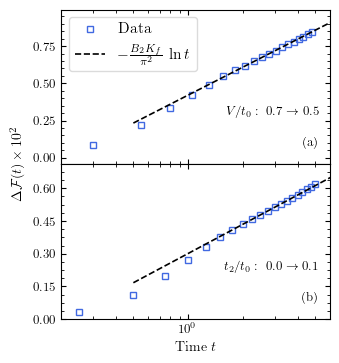

In [4]:
figure_X2_paper()

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.ticker import MaxNLocator, FixedLocator, FixedFormatter, NullFormatter

# compute_LL_parameter: unchanged. APS_RC and POSTER_RC: same dicts as in figure_1_poster.
# data_quench_dir, plot_dir: defined elsewhere in your notebook.


def figure_X2_poster():
    with plt.rc_context(POSTER_RC):

        fig = plt.figure(figsize=(7.5, 4.0))
        # wspace controls the gap between side-by-side panels; the panels have
        # different y-ranges, so each keeps its own y tick labels.
        spec = gridspec.GridSpec(nrows=1, ncols=2, wspace=0.18,
                                 left=0.11, right=0.99, top=0.85, bottom=0.20)
        ax1 = fig.add_subplot(spec[0, 0])
        ax2 = fig.add_subplot(spec[0, 1], sharex=ax1)

        m_spacing = 5
        m_size = 5.5
        m_ew = 1.2
        theory_label = r"$C \ln t$"

        # ----------------------------------------------- ax1: quench on V

        df_a = pd.read_csv(data_quench_dir / "NNN/quench_NNN_ctr-N1200_FillingFraction0.25_t20.1_V0.7.csv")

        times_a = df_a["Time"].values
        Fluctuations_a = df_a["Variance"].values

        n_a = 0.25
        t_2_a = 0.1
        V_i_a = 0.7
        V_f_a = 0.5
        t_0_a = 1
        K_i_a = compute_LL_parameter(n_a, V_i_a, t_0_a, t_2_a)
        K_f_a = compute_LL_parameter(n_a, V_f_a, t_0_a, t_2_a)

        B_param_a = 0.5 * (K_i_a**2 - K_f_a**2) / (K_i_a * K_f_a)
        m_theory_a = - B_param_a * K_f_a / (np.pi**2)

        Fluctuations_a = Fluctuations_a - Fluctuations_a[0]
        Fluctuations_a = Fluctuations_a[1:]
        times_a = times_a[1:]

        mask_a = (times_a >= 2.0) & (times_a <= 3.0)
        times_fit_a = times_a[mask_a]
        y_data_a = Fluctuations_a[mask_a]
        intercept_a = np.mean(y_data_a - m_theory_a * np.log(times_fit_a))

        t_line_a = np.linspace(0.5, 7, 200)
        theory_curve_a = m_theory_a * np.log(t_line_a) + intercept_a

        l_a_1, = ax1.semilogx(times_a, Fluctuations_a * 100, color='royalblue', marker='s',
                              markerfacecolor='none', linestyle='None',
                              markersize=m_size, markevery=m_spacing,
                              markeredgewidth=m_ew, label="Data")
        l_a_2, = ax1.semilogx(t_line_a, theory_curve_a * 100, color='black', linestyle='--',
                              linewidth=1.2, label=theory_label)

        ax1.text(0.05, 0.95, r"$V/t_0:\ 0.7 \to 0.5$", transform=ax1.transAxes,
                 ha='left', va='top', fontsize=18)
        ax1.text(0.96, 0.06, "(a)", transform=ax1.transAxes,
                 ha='right', va='bottom', weight='bold')

        # ----------------------------------------------- ax2: quench on t_2

        df_b = pd.read_csv(data_quench_dir / "NNN/quench_NN_to_NNN_ctr-N1200_FillingFraction0.25_t2i0.0_t2f0.2.csv")

        times_b = df_b["Time"].values
        Fluctuations_b = df_b["Variance"].values

        n_b = 0.25
        t_2_i_b = 0.0
        t_2_f_b = 0.2
        V_i_b = 0.5
        V_f_b = 0.5
        t_0_b = 1
        K_i_b = compute_LL_parameter(n_b, V_i_b, t_0_b, t_2_i_b)
        K_f_b = compute_LL_parameter(n_b, V_f_b, t_0_b, t_2_f_b)

        B_param_b = 0.5 * (K_i_b**2 - K_f_b**2) / (K_i_b * K_f_b)
        m_theory_b = - B_param_b * K_f_b / (np.pi**2)

        Fluctuations_b = Fluctuations_b - Fluctuations_b[0]
        Fluctuations_b = Fluctuations_b[1:]
        times_b = times_b[1:]

        mask_b = (times_b >= 2.0) & (times_b <= 3.0)
        times_fit_b = times_b[mask_b]
        y_data_b = Fluctuations_b[mask_b]
        intercept_b = np.mean(y_data_b - m_theory_b * np.log(times_fit_b))

        t_line_b = np.linspace(0.5, 7, 200)
        theory_curve_b = m_theory_b * np.log(t_line_b) + intercept_b

        ax2.semilogx(times_b, Fluctuations_b * 100, color='royalblue', marker='s',
                     markerfacecolor='none', linestyle='None',
                     markersize=m_size, markeredgewidth=m_ew)
        ax2.semilogx(t_line_b, theory_curve_b * 100, color='black', linestyle='--', linewidth=1.2)

        ax2.text(0.05, 0.95, r"$t_2/t_0:\ 0.0 \to 0.2$", transform=ax2.transAxes,
                 ha='left', va='top', fontsize=18)
        ax2.text(0.96, 0.06, "(b)", transform=ax2.transAxes,
                 ha='right', va='bottom', weight='bold')

        # ----------------------------------------------- shared formatting

        add_colored_legend(fig, fontsize=24, anchor=(0.5, 0.97))

        ax1.set_xlim(0.2, 6)   # sharex: sets both

        for ax in (ax1, ax2):
            ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
            # plain-number x ticks instead of a lone 10^0
            ax.xaxis.set_major_locator(FixedLocator([0.5, 1, 2, 5]))
            ax.xaxis.set_major_formatter(FixedFormatter(["0.5", "1", "2", "5"]))
            ax.xaxis.set_minor_formatter(NullFormatter())

        fig.supylabel(r"$\Delta\mathcal{F}_A(t)\times 10^{2}$", x=0.015, fontsize=18)
        fig.supxlabel(r"Time $t$", y=0.08, fontsize=18)

        fig.savefig(plot_dir / "figure_X2_poster.pdf")
        fig.savefig(plot_dir / "figure_X2_poster.png", dpi=300)
        plt.show()

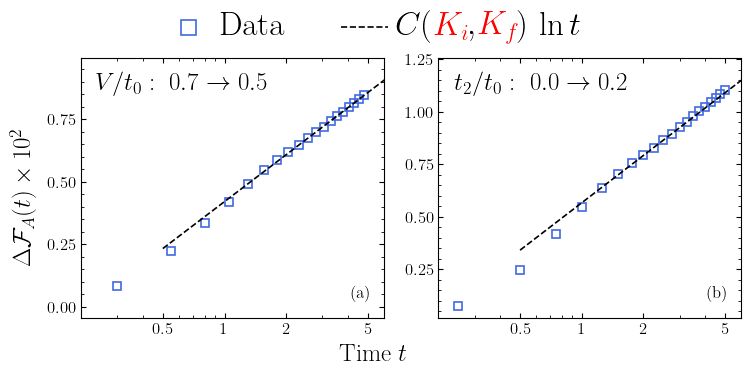

In [14]:
figure_X2_poster()

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.ticker import MaxNLocator, FixedLocator, FixedFormatter, NullFormatter
from scipy.stats import linregress
from matplotlib.lines import Line2D
from matplotlib.offsetbox import AnchoredOffsetbox, DrawingArea, HPacker, TextArea

def add_colored_legend(fig, fontsize=30, anchor=(0.5, 1.05),
                       data_color='royalblue', m_ew=1.2):
    """Figure legend: [square] Data     [dashed line] C(K_i, K_f) ln t,
    with K_i and K_f in red. Works in every backend (plain mathtext, no usetex)."""
 
    h = fontsize * 0.7
    w = fontsize * 1.4
 
    def piece(s, color='black'):
        return TextArea(s, textprops=dict(color=color, fontsize=fontsize))
 
    # handle for the data: open square
    marker_da = DrawingArea(w, h, 0, 0)
    marker_da.add_artist(Line2D([w / 2], [h / 2], marker='s', markersize=fontsize * 0.45,
                                markerfacecolor='none', markeredgecolor=data_color,
                                markeredgewidth=m_ew, linestyle='None'))
 
    # handle for the theory: dashed black line
    line_da = DrawingArea(w, h, 0, 0)
    line_da.add_artist(Line2D([0, w], [h / 2, h / 2], color='black',
                              linestyle='--', linewidth=1.2))
 
    # theory label made of separately colored pieces, aligned on the baseline
    theory = HPacker(
        children=[piece(r"$C($"),
                  piece(r"$K_i$", 'red'),
                  piece(r"$,\,$"),
                  piece(r"$K_f$", 'red'),
                  piece(r"$)\,\ln t$")],
        align='baseline', pad=0, sep=0)
 
    group_data = HPacker(children=[marker_da, piece("Data")],
                         align='center', pad=0, sep=6)
    group_theory = HPacker(children=[line_da, theory],
                           align='center', pad=0, sep=6)
    row = HPacker(children=[group_data, group_theory],
                  align='center', pad=0, sep=40)
 
    box = AnchoredOffsetbox(loc='upper center', child=row, pad=0, borderpad=0,
                            frameon=False, bbox_to_anchor=anchor,
                            bbox_transform=fig.transFigure)
    fig.add_artist(box)
    return box

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.ticker import MaxNLocator, FixedLocator, FixedFormatter, NullFormatter
from scipy.stats import linregress
from matplotlib.lines import Line2D
from matplotlib.offsetbox import AnchoredOffsetbox, DrawingArea, HPacker, TextArea

# compute_LL_parameter: unchanged. APS_RC: same dict as before.
# data_quench_dir, plot_dir: defined elsewhere in your notebook.

# Poster sizes: bigger text on top of the APS style
POSTER_RC = {
    **APS_RC,
    "font.size": 12,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 30,
}

def add_colored_legend(fig, fontsize=30, anchor=(0.5, 1.05),
                       data_color='royalblue', m_ew=1.2):
    """Figure legend: [square] Data     [dashed line] C(K_i, K_f) ln t,
    with K_i and K_f in red. Works in every backend (plain mathtext, no usetex)."""
 
    h = fontsize * 0.7
    w = fontsize * 1.4
 
    def piece(s, color='black'):
        return TextArea(s, textprops=dict(color=color, fontsize=fontsize))
 
    # handle for the data: open square
    marker_da = DrawingArea(w, h, 0, 0)
    marker_da.add_artist(Line2D([w / 2], [h / 2], marker='s', markersize=fontsize * 0.45,
                                markerfacecolor='none', markeredgecolor=data_color,
                                markeredgewidth=m_ew, linestyle='None'))
 
    # handle for the theory: dashed black line
    line_da = DrawingArea(w, h, 0, 0)
    line_da.add_artist(Line2D([0, w], [h / 2, h / 2], color='black',
                              linestyle='--', linewidth=1.2))
 
    # theory label made of separately colored pieces, aligned on the baseline
    theory = HPacker(
        children=[piece(r"$C($"),
                  piece(r"$K_i$", 'red'),
                  piece(r"$,\,$"),
                  piece(r"$K_f$", 'red'),
                  piece(r"$)\,\ln t$")],
        align='baseline', pad=0, sep=0)
 
    group_data = HPacker(children=[marker_da, piece("Data")],
                         align='center', pad=0, sep=6)
    group_theory = HPacker(children=[line_da, theory],
                           align='center', pad=0, sep=6)
    row = HPacker(children=[group_data, group_theory],
                  align='center', pad=0, sep=40)
 
    box = AnchoredOffsetbox(loc='upper center', child=row, pad=0, borderpad=0,
                            frameon=False, bbox_to_anchor=anchor,
                            bbox_transform=fig.transFigure)
    fig.add_artist(box)
    return box

def figure_1_poster():
    with plt.rc_context(POSTER_RC):

        fig = plt.figure(figsize=(9, 4.4))
        # wspace (not hspace!) controls the gap between side-by-side panels.
        # The panels have different y-ranges, so each keeps its own y tick labels
        # and needs a small gap for them.
        spec = gridspec.GridSpec(nrows=1, ncols=3, wspace=0.18,
                                 left=0.08, right=0.99, top=0.85, bottom=0.20)
        ax1 = fig.add_subplot(spec[0, 0])
        ax2 = fig.add_subplot(spec[0, 1], sharex=ax1)
        ax3 = fig.add_subplot(spec[0, 2], sharex=ax1)

        m_spacing = 5
        m_size = 5.5
        m_ew = 1.2
        theory_label = r"$C({\color{red}K_i}, {\color{red}K_f} ) \ln t$"

        # ----------------------------------------------- ax1

        df_a = pd.read_csv(data_quench_dir / "NNN/quench_NN_ctr-N1200_FillingFraction0.25_t20.0_V0.7.csv")

        times_a = df_a["Time"].values
        Fluctuations_a = df_a["Variance"].values

        n_a = 0.25
        t_2_a = 0
        V_i_a = 0.7
        V_f_a = 0.5
        t_0_a = 1
        K_i_a = compute_LL_parameter(n_a, V_i_a, t_0_a, t_2_a)
        K_f_a = compute_LL_parameter(n_a, V_f_a, t_0_a, t_2_a)

        B_param_a = 0.5 * (K_i_a**2 - K_f_a**2) / (K_i_a * K_f_a)
        m_theory_a = - B_param_a * K_f_a / (np.pi**2)

        Fluctuations_a = Fluctuations_a - Fluctuations_a[0]
        Fluctuations_a = Fluctuations_a[1:]
        times_a = times_a[1:]

        mask_a = (times_a >= 2.0) & (times_a <= 3.0)
        times_fit_a = times_a[mask_a]
        y_data_a = Fluctuations_a[mask_a]
        intercept_a = np.mean(y_data_a - m_theory_a * np.log(times_fit_a))

        t_line_a = np.linspace(0.5, 7, 200)
        theory_curve_a = m_theory_a * np.log(t_line_a) + intercept_a

        l_a_1, = ax1.semilogx(times_a, Fluctuations_a * 100, color='royalblue', marker='s',
                              markerfacecolor='none', linestyle='None',
                              markersize=m_size, markevery=m_spacing,
                              markeredgewidth=m_ew, label="Data")
        l_a_2, = ax1.semilogx(t_line_a, theory_curve_a * 100, color='black', linestyle='--',
                              linewidth=1.2, label=theory_label)

        ax1.text(0.05, 0.95, r"$n=1/4$", transform=ax1.transAxes, ha='left', va='top',  fontsize = 18)
        ax1.text(0.96, 0.06, "(a)", transform=ax1.transAxes, ha='right', va='bottom', weight='bold')

        # ----------------------------------------------- ax2

        df_b = pd.read_csv(data_quench_dir / "NNN/quench_NN_ctr-N1200_FillingFraction0.3333333333333333_t20.0_Vi0.7_Vf0.5.csv")

        times_b = df_b["Time"].values
        Fluctuations_b = df_b["Variance"].values

        n_b = 400 / 1200
        t_2_b = 0
        V_i_b = 0.7
        V_f_b = 0.5
        t_0_b = 1
        K_i_b = compute_LL_parameter(n_b, V_i_b, t_0_b, t_2_b)
        K_f_b = compute_LL_parameter(n_b, V_f_b, t_0_b, t_2_b)

        B_param_b = 0.5 * (K_i_b**2 - K_f_b**2) / (K_i_b * K_f_b)
        m_theory_b = - B_param_b * K_f_b / (np.pi**2)

        Fluctuations_b = Fluctuations_b - Fluctuations_b[0]
        Fluctuations_b = Fluctuations_b[1:]
        times_b = times_b[1:]

        mask_b = (times_b >= 2.0) & (times_b <= 3.0)
        times_fit_b = times_b[mask_b]
        y_data_b = Fluctuations_b[mask_b]
        intercept_b = np.mean(y_data_b - m_theory_b * np.log(times_fit_b))

        t_line_b = np.linspace(0.5, 7, 200)
        theory_curve_b = m_theory_b * np.log(t_line_b) + intercept_b

        ax2.semilogx(times_b, Fluctuations_b * 100, color='royalblue', marker='s',
                     markerfacecolor='none', linestyle='None',
                     markersize=m_size, markeredgewidth=m_ew)
        ax2.semilogx(t_line_b, theory_curve_b * 100, color='black', linestyle='--', linewidth=1.2)

        ax2.text(0.05, 0.95, r"$n=1/3$", transform=ax2.transAxes, ha='left', va='top',  fontsize = 18)
        ax2.text(0.96, 0.06, "(b)", transform=ax2.transAxes, ha='right', va='bottom', weight='bold')

        # ----------------------------------------------- ax3

        df_c = pd.read_csv(data_quench_dir / "NNN/quench_NN_ctr-N1200_FillingFraction0.5_t20.0_Vi0.7_Vf0.5.csv")

        times_c = df_c["Time"].values
        Fluctuations_c = df_c["Variance"].values

        # --- Bethe Ansatz parameters ---
        V_i_c = 0.7
        V_f_c = 0.5
        mu_i = np.arccos(V_i_c / 2)
        mu_f = np.arccos(V_f_c / 2)

        K_i_c = np.pi / (2 * (np.pi - mu_i))
        K_f_c = np.pi / (2 * (np.pi - mu_f))

        B_param_c = 0.5 * (K_i_c**2 - K_f_c**2) / (K_i_c * K_f_c)
        m_theory_c = - B_param_c * K_f_c / (np.pi**2)

        Fluctuations_c = Fluctuations_c - Fluctuations_c[0]
        Fluctuations_c = Fluctuations_c[1:]
        times_c = times_c[1:]

        mask_c = (times_c >= 2.0) & (times_c <= 3.0)
        times_fit_c = times_c[mask_c]
        y_data_c = Fluctuations_c[mask_c]
        intercept_c = np.mean(y_data_c - m_theory_c * np.log(times_fit_c))

        t_line_c = np.linspace(0.5, 7, 200)
        theory_curve_c = m_theory_c * np.log(t_line_c) + intercept_c

        ax3.semilogx(times_c, Fluctuations_c * 100, color='royalblue', marker='s',
                     markerfacecolor='none', linestyle='None',
                     markersize=m_size, markeredgewidth=m_ew)
        ax3.semilogx(t_line_c, theory_curve_c * 100, color='black', linestyle='--', linewidth=1.2)

        ax3.text(0.05, 0.95, r"$n=1/2$", transform=ax3.transAxes, ha='left', va='top', fontsize = 18)
        ax3.text(0.96, 0.06, "(c)", transform=ax3.transAxes, ha='right', va='bottom', weight='bold')

        # ----------------------------------------------- shared formatting

        add_colored_legend(fig, fontsize=30, anchor=(0.5, 0.97))

        ax1.set_xlim(0.2, 6)   # sharex: sets all three

        for ax in (ax1, ax2, ax3):
            ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
            # plain-number x ticks instead of a lone 10^0
            ax.xaxis.set_major_locator(FixedLocator([0.5, 1, 2, 5]))
            ax.xaxis.set_major_formatter(FixedFormatter(["0.5", "1", "2", "5"]))
            ax.xaxis.set_minor_formatter(NullFormatter())

        # y label on the left (you had supxlabel here), one shared x label at the bottom
        fig.supylabel(r"$\Delta\mathcal{F}_A(t)\times 10^{2}$", x=0.012, fontsize=18)
        fig.supxlabel(r"Time $t$", y=0.07, fontsize=18)

        fig.savefig(plot_dir / "figure_1_poster.pdf")
        fig.savefig(plot_dir / "figure_1_poster.png", dpi = 300)
        plt.show()

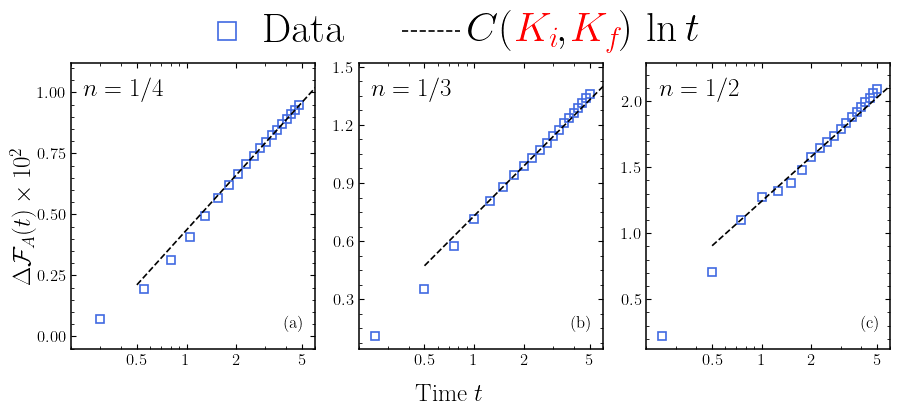

In [19]:
figure_1_poster()

In [ ]:
def figure_SSH_paper(): 
    
    
    df = pd.read_csv(data_quench_dir / "NNN/quench_SSH_ctr-N1200_FillingFraction0.25_v1.0_w0.2.csv")

    times = df["Time"].values
    Fluctuations = df["Variance"].values

    filling = 300 / 1000
    t_0 = 2.0 
    t_2 = 0.0
    V_i = 1.0
    V_f = 0.8
    
    def compute_LL_parameter(filling, V, t_0, t_2):
        fermi_velocity = 2 * t_0 * np.sin(np.pi * filling) + 4 * t_2 * np.sin(2 * np.pi * filling)
        numerator = fermi_velocity 
        denominator = fermi_velocity + (2* V / np.pi) * (1 - np.cos(2 * np.pi * filling))
        return np.sqrt(numerator / denominator)

    def compute_LL_sound_velocity(filling, V, t_0, t_2):
        fermi_velocity = 2 * t_0 * np.sin(np.pi * filling) + 4 * t_2 * np.sin(2 * np.pi * filling)
        first_term = fermi_velocity + (V / np.pi) * np.cos(2 * np.pi * filling)
        second_term = fermi_velocity + (V / np.pi) * (2 - np.cos(2 * np.pi * filling))
        return np.sqrt(first_term * second_term)
    


    K_i = compute_LL_parameter(filling, V_i, t_0, t_2)
    K_f = compute_LL_parameter(filling, V_f, t_0, t_2)
    u_f = compute_LL_sound_velocity(filling, V_f, t_0, t_2)

    print(f"Initial LL parameter: {K_i:.5f}")
    print(f"Final LL paramter: {K_f:.5f}")
    print(f"Final sound velocity: {u_f:.5f}")

    B_param = 0.5 * (K_i**2 - K_f**2) / (K_i * K_f)
    m_theory = - B_param * K_f / ( np.pi**2) 


    Fluctuations = Fluctuations - Fluctuations[0]  
    Fluctuations = Fluctuations[1:]
    times = times[1:]

    # --- perform fit ---
    mask = (times >= 2.0) & (times <= 5.0)
    times_fit = times[mask]
    Fluctuations_fit = Fluctuations[mask]
    x_data = np.log(times_fit)
    y_data = Fluctuations_fit
    slope, intercept, r_value, p_value, std_err = linregress(x_data, y_data)
    
    #print(f"Fit Results: slope = {slope:.6f}, intercept = {intercept:.6f}, R-squared = {r_value**2:.6f}")
    #print(f"m_theory:  {m_theory:.6f}, m_fit: {slope:.6f}, error_percentage: {abs((slope - m_theory)/m_theory)*100:.2f}%")
    
    t_line = np.linspace(0.5, 7, 200)
    # fit_curve = slope * np.log(t_line) + intercept
    theory_curve = m_theory * np.log(t_line) + intercept 

    # --- Plotting ---
    fig = plt.figure(figsize=(6, 4))
    spec = gridspec.GridSpec(nrows=1, ncols=1)
    ax = fig.add_subplot(spec[0, 0])

    # Plot data using open markers and no connecting lines to mimic Fig 4
    # The 'markevery' parameter prevents the markers from clustering too heavily if you have many data points
    m_spacing = 5
    
    l4, = ax.plot(times, Fluctuations, color='royalblue', marker='p', markerfacecolor= 'none',
                          linestyle='None', label=r"Data $(N=1200)$")
    
    
    # Plot theory as a dashed black line, similar to the reference lines in the paper
    #l6, = ax.semilogx(t_line, theory_curve, color='black', linestyle='--', linewidth=1.0)

    # Axes and grid styling
    ax.set_xlabel(r"Time $t$", fontsize=16)
    ax.set_ylabel(r"Fluctuations $\Delta \mathcal{F}(t)$", fontsize=14)
    ax.tick_params(axis='both', which='major', direction='in', labelsize=14)
    ax.tick_params(axis='both', which='minor', direction='in')
    # ax.set_xlim(0.4, 5.5)
    # ax.set_ylim(0.0024, 0.0125)
    
    # Keeping grid subtle
    ax.grid(False)
    ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0), useMathText=True)
    ax.yaxis.get_offset_text().set_fontsize(14)
    
    # Legend
    leg = ax.legend(handles=[l4], fontsize=16, loc='best', frameon=True, edgecolor= 'lightgray')

    # --- Adding the Annotation Arrow ---
    target_x = 0.7
    target_y = intercept - 0.0015
    
    # Adjust xytext to move the starting point of the text/arrow. 
    # Here it places the text slightly to the left (0.6) and up (+0.003) from the line.
    


    plt.tight_layout()
    plt.savefig(plot_dir / "figure_SSH.pdf", dpi=300)

    plt.show()

Initial LL parameter: 0.89175
Final LL paramter: 0.91059
Final sound velocity: 3.47476


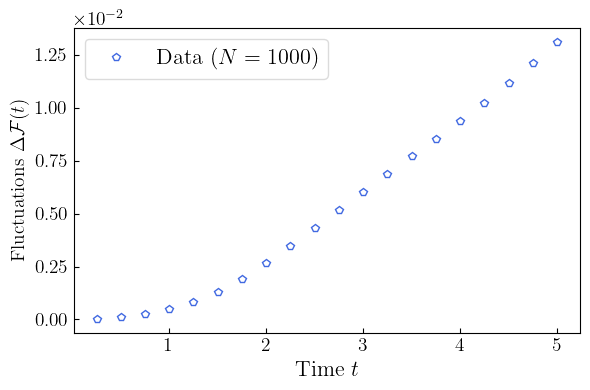

In [5]:
figure_SSH_paper()

In [ ]:
def compute_LL_parameter(filling, V, t_0, t_2):
    fermi_velocity = 2 * t_0 * np.sin(np.pi * filling) + 4 * t_2 * np.sin(2 * np.pi * filling)
    numerator = fermi_velocity 
    denominator = fermi_velocity + (2 * V / np.pi) * (1 - np.cos(2 * np.pi * filling))
    return np.sqrt(numerator / denominator)

def compute_LL_sound_velocity(filling, V, t_0, t_2):
    fermi_velocity = 2 * t_0 * np.sin(np.pi * filling) + 4 * t_2 * np.sin(2 * np.pi * filling)
    first_term = fermi_velocity + (V / np.pi) * np.cos(2 * np.pi * filling)
    second_term = fermi_velocity + (V / np.pi) * (2 - np.cos(2 * np.pi * filling))
    return np.sqrt(first_term * second_term)

def figure_X_paper(): 
    
    # 1. Define the filling fractions you want to plot
    filling_fractions = [0.1, 0.2, 0.3, 0.4, 0.5]
    
    # System parameters
    t_0 = 2.0 
    t_2 = 0.0
    V_i = 1.0
    V_f = 0.8
    N = 1000 # Total number of sites

    # 2. Set up distinct colors and markers for the loop
    colors = plt.cm.viridis(np.linspace(0, 0.9, len(filling_fractions)))
    markers = ['p', 'o', 's', '^', 'D']
    
    # --- Plot Setup ---
    fig = plt.figure(figsize=(8, 5))
    spec = gridspec.GridSpec(nrows=1, ncols=1)
    ax = fig.add_subplot(spec[0, 0])
    
    # Store handles for the legend
    legend_handles = []

    # 3. Loop through each filling fraction
    for idx, filling in enumerate(filling_fractions):
        
        # Dynamically construct the filename
        filename = f"quench_NN_ctr-N{N}_FillingFraction{filling}_t20.0_V1.0.csv"
        file_path = data_quench_dir / "NNN" / filename
        
        # Check if file exists to prevent crashing if a simulation isn't done yet
        if not file_path.exists():
            print(f"File not found, skipping: {filename}")
            continue

        # Load data
        df = pd.read_csv(file_path)
        times = df["Time"].values
        Fluctuations = df["Variance"].values

        # Compute parameters
        K_i = compute_LL_parameter(filling, V_i, t_0, t_2)
        K_f = compute_LL_parameter(filling, V_f, t_0, t_2)
        u_f = compute_LL_sound_velocity(filling, V_f, t_0, t_2)

        print(f"--- Filling Fraction: {filling} ---")
        print(f"Initial LL parameter: {K_i:.5f} | Final LL param: {K_f:.5f} | Final sound velocity: {u_f:.5f}")

        B_param = 0.5 * (K_i**2 - K_f**2) / (K_i * K_f)
        m_theory = - B_param * K_f / (np.pi**2) 

        # Normalize fluctuations
        Fluctuations = Fluctuations - Fluctuations[0]  
        Fluctuations = Fluctuations[1:]
        times = times[1:]

        # --- Perform fit to find the intercept for the theory line ---
        mask = (times >= 3.0) & (times <= 5.0)
        times_fit = times[mask]
        Fluctuations_fit = Fluctuations[mask]
        x_data = np.log(times_fit)
        y_data = Fluctuations_fit
        slope, intercept, r_value, p_value, std_err = linregress(x_data, y_data)
        
        t_line = np.linspace(0.5, 7, 200)
        theory_curve = m_theory * np.log(t_line) + intercept

        # --- Plotting the Data and Theory for this iteration ---
        m_spacing = 5
        color = colors[idx]
        marker = markers[idx % len(markers)]
        
        # Calculate N particles for the label (e.g., 0.1 * 1000 = 100)
        n_particles = int(filling * N)
        label_str = rf"$n = {filling} = \frac{{{n_particles}}}{{{N}}}$"
        
        # Plot Scatter Data
        data_line, = ax.semilogx(times, Fluctuations, color=color, marker=marker, 
                                 markerfacecolor='none', linestyle='None', 
                                 markevery=m_spacing, label=label_str)
        
        # Plot Theory Curve (dashed line matching the data color)
        ax.semilogx(t_line, theory_curve, color=color, linestyle='--', linewidth=1.2, alpha=0.8)
        
        legend_handles.append(data_line)

    # --- Axes and grid styling ---
    ax.set_xlabel(r"time $t$", fontsize=16)
    ax.set_ylabel(r"$\Delta \mathcal{F}(t)$", fontsize=16)
    ax.tick_params(axis='both', which='major', direction='in', labelsize=14)
    ax.tick_params(axis='both', which='minor', direction='in')
    
    ax.grid(True, which="major", linestyle='--', alpha=0.4)
    ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0), useMathText=True)
    ax.yaxis.get_offset_text().set_fontsize(14)
    
    # 4. Generate a unified legend
    ax.legend(handles=legend_handles, fontsize=12, loc='best', frameon=True, edgecolor='lightgray')

    plt.tight_layout()
    plt.savefig(plot_dir / "figure_X.pdf", dpi=300)
    plt.show()

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import linregress

def figure_7_paper(): 
    # APS style rcParams
    plt.rcParams.update({
        "text.usetex": True,
        "font.family": "serif",
        "font.serif": ["Computer Modern Roman"],
        "axes.linewidth": 1.1,
        "axes.labelsize": 12,
        "xtick.labelsize": 10.5,
        "ytick.labelsize": 10.5,
        "legend.fontsize": 10,
    })
    
    file_path = data_quench_dir / "NNN/quench_NN_to_NNN_ctr-N1000_FillingFraction0.3_t20.0_V0.5.csv"
    if not file_path.exists():
        raise FileNotFoundError(f"Missing data file: {file_path}")

    df2 = pd.read_csv(file_path)
    times2 = df2["Time"].values
    Fluctuations2 = df2["Variance"].values

    def compute_LL_parameter(filling, V, t_0, t_2):
        fermi_velocity = 2 * t_0 * np.sin(np.pi * filling) + 4 * t_2 * np.sin(2 * np.pi * filling)
        numerator = fermi_velocity 
        denominator = fermi_velocity + (2 * V / np.pi) * (1 - np.cos(2 * np.pi * filling))
        return np.sqrt(numerator / denominator)

    filling = 0.3
    t_0 = 1.0 
    t_2_i = 0.0
    t_2_f = 0.1
    interaction = 0.5

    K_i = compute_LL_parameter(filling, interaction, t_0, t_2_i)
    K_f = compute_LL_parameter(filling, interaction, t_0, t_2_f)

    B_param = 0.5 * (K_i**2 - K_f**2) / (K_i * K_f)
    m_theory = - B_param * K_f / (np.pi**2)

    Fluctuations2 = Fluctuations2 - Fluctuations2[0]  
    Fluctuations2 = Fluctuations2[1:]
    times2 = times2[1:]

    # --- Fit range ---
    mask = (times2 >= 2.0) & (times2 <= 3.0)
    times_fit = times2[mask]
    Fluctuations_fit = Fluctuations2[mask]
    slope, intercept, r_val, _, _ = linregress(np.log(times_fit), Fluctuations_fit)
    
    t_line = np.linspace(0.4, 6.0, 200)
    theory_curve = m_theory * np.log(t_line) + intercept

    # --- Plotting ---
    # APS single-column standard width is 3.375 in (8.6 cm)
    fig, ax = plt.subplots(figsize=(6, 4))

    m_spacing = 5
    m_size = 6.0
    m_ew = 1.2

    # 1. Provide an explicit label to eliminate MatplotlibDeprecationWarning
    l4, = ax.semilogx(times2, Fluctuations2, color='royalblue', marker='s', 
                      markerfacecolor='none', linestyle='None', 
                      markevery=m_spacing, markersize=m_size, 
                      markeredgewidth=m_ew, label=r"Data ($N=1000$)")

    # 2. Theory curve
    l6, = ax.semilogx(t_line, theory_curve, color='black', linestyle='--', 
                      linewidth=1.2, label=r"$-\frac{B_2 K_f}{\pi^2} \ln(t)$")


    # 4. Limits and framing
    ax.set_xlim(0.11, 6.0)
    ax.set_ylim(-0.0005, 0.010)

    ax.set_xlabel(r"Time $t$")
    ax.set_ylabel(r"Fluctuations $\Delta \mathcal{F}(t)$")
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)

    ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0), useMathText=True)
    ax.yaxis.get_offset_text().set_fontsize(10.5)

    # 5. Proportional, clean legend
    ax.legend(loc='upper left', frameon=True, handletextpad=0.4, fontsize=18,
              borderpad=0.2, labelspacing=0.35)

    plt.tight_layout(pad=0.4)
    plt.savefig(plot_dir / "figure_7.pdf", dpi=300)
    plt.show()

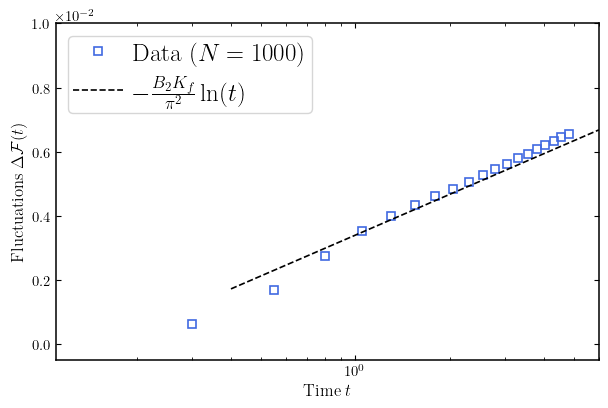

In [15]:
figure_7_paper()

In [5]:
def compute_LL_parameter(filling, V, t_0, t_2):
    fermi_velocity = 2 * t_0 * np.sin(np.pi * filling) + 4 * t_2 * np.sin(2 * np.pi * filling)
    numerator = fermi_velocity 
    denominator = fermi_velocity + (2* V / np.pi) * (1 - np.cos(2 * np.pi * filling))
    return np.sqrt(numerator / denominator)

def compute_LL_sound_velocity(filling, V, t_0, t_2):
    fermi_velocity = 2 * t_0 * np.sin(np.pi * filling) + 4 * t_2 * np.sin(2 * np.pi * filling)
    first_term = fermi_velocity + (V / np.pi) * np.cos(2 * np.pi * filling)
    second_term = fermi_velocity + (V / np.pi) * (2 - np.cos(2 * np.pi * filling))
    return np.sqrt(first_term * second_term)


from matplotlib.ticker import MaxNLocator

APS_RC = {
    "font.family": "serif",
    "mathtext.fontset": "cm",
    "font.size": 9,
    "axes.labelsize": 10,
    "legend.fontsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    # ticks on all four sides, pointing inward, with minor ticks
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "xtick.minor.visible": True,
    "ytick.minor.visible": True,
    # embed TrueType fonts (Type 42) instead of Type 3
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
}

def figure_SSHX_paper(): 
    with plt.rc_context(APS_RC):

        # Setting the figures
        fig = plt.figure(figsize=(3.4, 3.6))
        spec = gridspec.GridSpec(nrows=2, ncols=1, hspace=0, left=0.18, right=0.97, top=0.98, bottom=0.12)
        ax1 = fig.add_subplot(spec[0, 0])
        ax2 = fig.add_subplot(spec[1, 0], sharex=ax1)

        m_spacing = 5
        m_size = 4.5
        m_ew = 1.0
        theory_label = r"$-\frac{B_2 K_f}{\pi^2}\,\ln t$"

        # ----------------------------------------------- ax1 

        df_a = pd.read_csv(data_quench_dir / "NNN/quench_SSH_ctr-N1200_FillingFraction0.25_wi0.2_wf0.3.csv")

        times_a = df_a["Time"].values
        Fluctuations_a = df_a["Variance"].values

        # n_a = 0.25
        # t_2_a = 0.1
        # V_i_a = 0.7
        # V_f_a = 0.5
        # t_0_a = 1
        # K_i_a = compute_LL_parameter(n_a, V_i_a, t_0_a, t_2_a)
        # K_f_a = compute_LL_parameter(n_a, V_f_a, t_0_a, t_2_a)

        # B_param_a = 0.5 * (K_i_a**2 - K_f_a**2) / (K_i_a * K_f_a)
        # m_theory_a = - B_param_a * K_f_a / ( np.pi**2) 

        # Fluctuations_a = Fluctuations_a - Fluctuations_a[0]  
        # Fluctuations_a = Fluctuations_a[1:]
        # times_a = times_a[1:]

        # # --- perform fit ---
        # mask_a = (times_a >= 2.0) & (times_a <= 3.0)
        # times_fit_a = times_a[mask_a]
        # Fluctuations_fit_a = Fluctuations_a[mask_a]
        # x_data_a = np.log(times_fit_a)
        # y_data_a = Fluctuations_fit_a
        # slope, intercept_a, r_value, p_value, std_err = linregress(x_data_a, y_data_a)
        # intercept_a = np.mean(y_data_a - m_theory_a * np.log(times_fit_a))

        # t_line_a = np.linspace(0.5, 7, 200)
        # # fit_curve = slope * np.log(t_line) + intercept
        # theory_curve_a = m_theory_a * np.log(t_line_a) + intercept_a 


        # 1. Provide an explicit label to eliminate MatplotlibDeprecationWarning
        l_a_1, = ax1.plot(times_a, Fluctuations_a*100, color='royalblue', marker='s', 
                            markerfacecolor='none', linestyle='None', 
                            markersize=m_size,
                            markeredgewidth=m_ew, label=r"Data")

        ax1.legend(handles=[l_a_1], loc='upper left', frameon=True, edgecolor = 'lightgray')
        ax1.text(0.96, 0.10, r"(a)", transform=ax1.transAxes, ha='right', va ='bottom', weight= 'bold')
        
        # -------------------------------------------- ax2
        df_b = pd.read_csv(data_quench_dir / "NNN/quench_SSH_ctr-N1200_FillingFraction0.25_Vi0.7_Vf0.5.csv")

        times_b = df_b["Time"].values
        Fluctuations_b = df_b["Variance"].values

        # n_b = 0.25
        # t_2_i_b = 0.0
        # t_2_f_b = 0.1
        # V_i_b = 0.5
        # V_f_b = 0.5
        # t_0_b = 1
        # K_i_b = compute_LL_parameter(n_b, V_i_b, t_0_b, t_2_i_b)
        # K_f_b = compute_LL_parameter(n_b, V_f_b, t_0_b, t_2_f_b)

        # B_param_b = 0.5 * (K_i_b**2 - K_f_b**2) / (K_i_b * K_f_b)
        # m_theory_b = - B_param_b * K_f_b / ( np.pi**2) 

        # Fluctuations_b = Fluctuations_b - Fluctuations_b[0]  
        # Fluctuations_b = Fluctuations_b[1:]
        # times_b = times_b[1:]

        # # --- perform fit ---
        # mask_b = (times_b >= 2.0) & (times_b <= 3.0)
        # times_fit_b = times_b[mask_b]
        # Fluctuations_fit_b = Fluctuations_b[mask_b]
        # x_data_b = np.log(times_fit_b)
        # y_data_b = Fluctuations_fit_b
        # slope, intercept_b, r_value, p_value, std_err = linregress(x_data_b, y_data_b)
        # intercept_b = np.mean(y_data_b - m_theory_b * np.log(times_fit_b))

        # t_line_b = np.linspace(0.5, 7, 200)
        # theory_curve_b = m_theory_b * np.log(t_line_b) + intercept_b


        l_b_1, = ax2.plot(times_b, Fluctuations_b*100, color='royalblue', marker='s', 
                            markerfacecolor='none', linestyle='None', 
                            markersize=m_size,
                            markeredgewidth=m_ew)


        ax2.text(0.96, 0.10, r"(b)", transform=ax2.transAxes, ha='right', va ='bottom', weight= 'bold')


        #------------------------------- shared stuff
        ax1.set_xlim(0.2, 6)
        ax2.set_xlabel(r"Time $t$")
        fig.supylabel(r"$\Delta\mathcal{F}(t)\times 10^{2}$", x=0.03, y=0.55, fontsize=10)
        ax1.tick_params(axis='x', labelbottom=False)
        for ax in (ax1, ax2):
            ax.yaxis.set_major_locator(MaxNLocator(nbins=5))

        fig.canvas.draw()  # make sure autoscaling and limits are settled

        for ax in (ax1, ax2):
            ymin, ymax = ax.get_ylim()
            margin = 0.06 * (ymax - ymin)
            ticks = [t for t in ax.get_yticks() if ymin <= t <= ymax - margin]
            ax.set_yticks(ticks)

        ax1.text(0.96, 0.25, r"$w_i/v = 0.2 \to w_f/v = 0.3$", transform=ax1.transAxes,
         ha='right', va='bottom', weight='bold')
        ax2.text(0.96, 0.25, r"$V_i/v = 0.7 \to V_f/v = 0.5$", transform=ax2.transAxes,
         ha='right', va='bottom', weight='bold')

        plt.savefig(plot_dir / "figure_SSHX.pdf", dpi=300)

        plt.show()

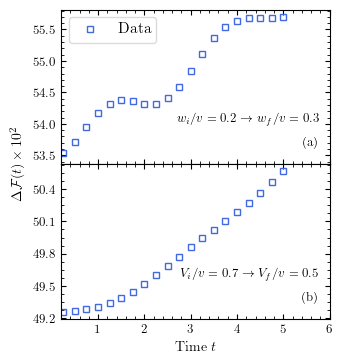

In [6]:
figure_SSHX_paper()